# Telugu Handwritten Character OCR 

## 1. Setup & configuration

In [1]:
import os, sys, json, time, copy, random, shutil, math, warnings
from collections import Counter
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm

import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
import torchvision
from torchvision.models import mobilenet_v3_small, MobileNet_V3_Small_Weights

from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, confusion_matrix,
                             classification_report)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")

# ----------------------------- CONFIG -----------------------------
ROOT = "/kaggle/input/datasets/pavankalyand515/data-telugu-handwritten/Final Dataset of Telugu Handwritten Chararcters/Test1"
GROUPS = ["Guninthamulu", "achulu", "hallulu", "othulu"]   # sub-folders of ROOT

IMG_SIZE      = 96        # characters are resized/padded to IMG_SIZE x IMG_SIZE
BATCH_SIZE    = 64
EPOCHS        = 30
LR            = 1e-3
WEIGHT_DECAY  = 1e-4
PATIENCE      = 7         # early stopping on validation accuracy
MIN_PER_CLASS = 5         # classes with fewer images are dropped
MERGE_BY_UNICODE    = True   # folders that are the SAME Telugu character (ka in Guninthamulu & hallulu, d/da, ch/cha ...) -> ONE class
MAX_PER_GROUP_CLASS = 1000   # cap images per (class, source-group): stops Guninthamulu (84% of data) from dominating
BALANCE_POWER       = 1.0    # train sampler weight = 1/count**power  (1 = fully class-balanced batches, 0 = natural)
VAL_FRAC, TEST_FRAC = 0.15, 0.15
USE_PRETRAINED = True     # ImageNet weights for MobileNetV3 (falls back to random init if offline)
SEED = 42
QUICK_TEST = False        # True -> tiny run (2 epochs, <=30 imgs/class) to check the pipeline

OUT_DIR = "/kaggle/working" if os.path.isdir("/kaggle/working") else "./outputs"
MODEL_DIR, FIG_DIR, REP_DIR = [os.path.join(OUT_DIR, d) for d in ("models", "figures", "reports")]
for d in (MODEL_DIR, FIG_DIR, REP_DIR): os.makedirs(d, exist_ok=True)

def seed_everything(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
seed_everything(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
NUM_WORKERS = min(4, os.cpu_count() or 1)
if QUICK_TEST: EPOCHS = 2
print("torch", torch.__version__, "| torchvision", torchvision.__version__, "| device:", DEVICE,
      "|", torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "CPU")

def savefig(name):
    plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, name), dpi=150, bbox_inches="tight"); plt.show()

torch 2.11.0+cu128 | torchvision 0.26.0+cu128 | device: cuda | Tesla T4


## 2. Helper library (preprocessing, stroke features, Unicode, dictionary correction)

The helper code lives in one string so that the **exact same** functions are written to `ocr_utils.py` and re-used by the Flask app at deployment time (no train/serve skew).

* `preprocess_gray` – polarity fix → **crop to ink + square canvas** → resize → **non-local-means noise removal** → **CLAHE**
* `compute_stroke_maps` – 3-channel stroke descriptor: **skeleton**, **stroke width** (distance transform), **edge magnitude**
* `telugu_units`, `edit_distance`, `correct_word` – akshara-level dictionary correction

In [2]:
UTIL_SRC = r'''
import re
import cv2
import numpy as np
from skimage.morphology import skeletonize

def decode_gray(data):
    # bytes of an image file -> uint8 gray, transparent pixels become WHITE.
    # Used by BOTH training and the Flask app (no train/serve skew).
    try:
        img = cv2.imdecode(np.frombuffer(data, dtype=np.uint8), cv2.IMREAD_UNCHANGED)
    except Exception:
        return None
    if img is None:
        return None
    if img.dtype != np.uint8:
        img = cv2.normalize(img, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)
    if img.ndim == 3 and img.shape[2] == 4:
        alpha = img[:, :, 3:4].astype(np.float32) / 255.0
        rgb = img[:, :, :3].astype(np.float32)
        img = (rgb * alpha + 255.0 * (1.0 - alpha)).astype(np.uint8)
    if img.ndim == 3:
        img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    return img

def load_image_gray(path):
    # robust loader (handles unicode/space paths and RGBA images); returns uint8 gray or None
    try:
        return decode_gray(np.fromfile(path, dtype=np.uint8).tobytes())
    except Exception:
        return None

def crop_to_ink(img, margin=0.15):
    # img: dark ink on light paper. Crop to the ink bounding box (+margin) and return a SQUARE canvas,
    # so the character always fills the frame however much white space the uploaded image has.
    h0, w0 = img.shape[:2]
    bg = int(np.percentile(img, 90))
    blur = cv2.GaussianBlur(img, (3, 3), 0)
    _, ink = cv2.threshold(blur, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
    x0, y0, x1, y1 = 0, 0, w0, h0                      # fallback = whole image
    if (ink > 0).mean() < 0.6:                         # >60% "ink" means a bad threshold -> keep whole image
        n, _, st, _ = cv2.connectedComponentsWithStats(ink, connectivity=8)
        min_area = max(3, int(0.0002 * h0 * w0))       # drop dust, but keep small dots (anusvara / visarga)
        keep = [i for i in range(1, n) if st[i, cv2.CC_STAT_AREA] >= min_area]
        if keep:
            x0 = min(st[i, cv2.CC_STAT_LEFT] for i in keep)
            y0 = min(st[i, cv2.CC_STAT_TOP] for i in keep)
            x1 = max(st[i, cv2.CC_STAT_LEFT] + st[i, cv2.CC_STAT_WIDTH] for i in keep)
            y1 = max(st[i, cv2.CC_STAT_TOP] + st[i, cv2.CC_STAT_HEIGHT] for i in keep)
    crop = img[y0:y1, x0:x1]
    ch, cw = crop.shape[:2]
    side = max(int(round(max(ch, cw) * (1 + 2 * margin))), 8)
    canvas = np.full((side, side), bg, dtype=np.uint8)
    oy, ox = (side - ch) // 2, (side - cw) // 2
    canvas[oy:oy + ch, ox:ox + cw] = crop
    return canvas

def preprocess_gray(img, size=96, margin=0.15):
    # 1) polarity -> dark ink on light paper
    if np.median(img) < 127:
        img = 255 - img
    # 2) crop to the strokes, centre on a square canvas, resize
    img = crop_to_ink(img, margin)
    img = cv2.resize(img, (size, size), interpolation=cv2.INTER_AREA)
    # 3) noise removal
    img = cv2.fastNlMeansDenoising(img, None, h=10, templateWindowSize=5, searchWindowSize=15)
    # 4) CLAHE contrast enhancement
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(4, 4))
    return clahe.apply(img)

def compute_stroke_maps(gray):
    # 3-channel stroke descriptor: skeleton, stroke-width (distance transform), edge magnitude
    _, ink = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
    skel = skeletonize(ink > 0).astype(np.float32)
    dist = cv2.distanceTransform(ink, cv2.DIST_L2, 3)
    dist = dist / max(float(dist.max()), 1e-6)
    gx = cv2.Sobel(gray, cv2.CV_32F, 1, 0, ksize=3)
    gy = cv2.Sobel(gray, cv2.CV_32F, 0, 1, ksize=3)
    mag = np.sqrt(gx * gx + gy * gy)
    mag = mag / max(float(mag.max()), 1e-6)
    return np.stack([skel, dist, mag]).astype(np.float32)

# ---------- Telugu text helpers (unicode units + dictionary correction) ----------
def telugu_units(text):
    # split a string into aksharas: base char + following signs; a virama glues the next consonant
    units, cur, glue = [], "", False
    for ch in text:
        cp = ord(ch)
        is_sign = (0x0C3E <= cp <= 0x0C56) or (0x0C00 <= cp <= 0x0C03)
        if cur and (is_sign or glue):
            cur += ch
            glue = (cp == 0x0C4D)
        else:
            if cur:
                units.append(cur)
            cur, glue = ch, False
    if cur:
        units.append(cur)
    return units

def edit_distance(a, b):
    prev = list(range(len(b) + 1))
    for i, x in enumerate(a, 1):
        curr = [i]
        for j, y in enumerate(b, 1):
            curr.append(min(prev[j] + 1, curr[j - 1] + 1, prev[j - 1] + (x != y)))
        prev = curr
    return prev[-1]

def correct_word(word, dictionary_units, max_dist=None):
    # dictionary_units: dict {word: list_of_units}. returns (best_word, distance)
    u = telugu_units(word)
    if not u:
        return word, 0
    if max_dist is None:
        max_dist = 1 if len(u) <= 4 else 2
    best, best_d = word, max_dist + 1
    for w, wu in dictionary_units.items():
        if abs(len(wu) - len(u)) > max_dist:
            continue
        d = edit_distance(u, wu)
        if d < best_d:
            best, best_d = w, d
            if d == 0:
                break
    return (best, best_d) if best_d <= max_dist else (word, -1)
'''

exec(UTIL_SRC)
with open(os.path.join(OUT_DIR, 'ocr_utils.py'), 'w', encoding='utf-8') as f:
    f.write(UTIL_SRC)
print('helpers loaded; saved ->', os.path.join(OUT_DIR, 'ocr_utils.py'))

helpers loaded; saved -> /kaggle/working/ocr_utils.py


## 3. Dataset discovery

In [3]:
IMG_EXT = {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff", ".webp"}
import re

rows = []
for g in GROUPS:
    gdir = os.path.join(ROOT, g)
    if not os.path.isdir(gdir):
        print(f"[WARN] missing folder: {gdir}"); continue
    for dp, _, files in os.walk(gdir):
        rel = os.path.relpath(dp, gdir)
        for fn in files:
            stem, ext = os.path.splitext(fn)
            if ext.lower() not in IMG_EXT: continue
            if rel != ".":
                sub = rel.split(os.sep)[0]                       # class = first sub-folder under the group
            else:
                sub = re.sub(r"[\d_\-\s\(\)]+$", "", stem) or g   # images directly in group folder -> class from file name
            rows.append((os.path.join(dp, fn), g, sub))

df = pd.DataFrame(rows, columns=["path", "group", "sub"])
df["key"] = df["group"] + "/" + df["sub"]
print("Total images found:", len(df))
print(df.groupby("group").agg(images=("path", "count"), classes=("key", "nunique")))
print("\nExample class folders per group:")
for g in GROUPS:
    print(f"  {g}:", sorted(df[df["group"] == g]["sub"].unique())[:12])

# drop tiny classes
cnt = df["key"].value_counts()
keep = cnt[cnt >= MIN_PER_CLASS].index
if len(keep) < len(cnt): print(f"\nDropping {len(cnt)-len(keep)} classes with < {MIN_PER_CLASS} images")
df = df[df["key"].isin(keep)].reset_index(drop=True)
RAW_GROUP_COUNTS = df["group"].value_counts()
print(f"\nFolders (raw classes): {df['key'].nunique()} | images: {len(df)}")
print("Final class labels are built in section 3.1 after merging folders that are the same character.")


Total images found: 292752
              images  classes
group                        
Guninthamulu  245173       34
achulu          9546       16
hallulu        19598       35
othulu         18435       36

Example class folders per group:
  Guninthamulu: ['RR', 'ana', 'ba', 'bha', 'ch', 'cha', 'd', 'da', 'dh', 'dha', 'ga', 'gha']
  achulu: ['a', 'aa', 'ah', 'ai', 'am', 'ao', 'e', 'ee', 'i', 'ii', 'o', 'oo']
  hallulu: ['P', 'Ph', 'ana', 'b', 'bh', 'ch', 'cha', 'd', 'da', 'dh', 'dha', 'g']
  othulu: ['an', 'b', 'bh', 'c', 'ch', 'd', 'da', 'dh', 'dha', 'g', 'gh', 'h']

Folders (raw classes): 121 | images: 292752
Final class labels are built in section 3.1 after merging folders that are the same character.


### 3.1 Class → Telugu Unicode mapping, merging duplicates, balancing
Folder names are transliterations (e.g. `ka`, `kaa`), so they are resolved to Telugu Unicode. **Check the printed table** and fix anything wrong with `MANUAL_UNICODE`.

Then (this is the main fix):
1. folders that give the **same Unicode** become **one class** (e.g. `Guninthamulu/ka` + `hallulu/ka`, `d` + `da`, `ch` + `cha`)
2. images per *(class, source group)* are capped at `MAX_PER_GROUP_CLASS`, so no group swamps the others


In [4]:
UNI_SRC = r'''
import re

TELUGU_RE = re.compile(r"[\u0C00-\u0C7F]")
VIRAMA = "\u0C4D"

VOWELS = {  # achulu
    "a": "అ", "aa": "ఆ", "i": "ఇ", "ii": "ఈ", "u": "ఉ", "uu": "ఊ", "ru": "ఋ", "ruu": "ౠ",
    "e": "ఎ", "ee": "ఏ", "ai": "ఐ", "o": "ఒ", "oo": "ఓ", "au": "ఔ", "am": "అం", "ah": "అః",
}
VOWEL_SIGNS = {  # used for guninthamulu (consonant + vowel sign); "a" is the inherent vowel
    "a": "", "aa": "ా", "i": "ి", "ii": "ీ", "u": "ు", "uu": "ూ", "ru": "ృ", "ruu": "ౄ",
    "e": "ె", "ee": "ే", "ai": "ై", "o": "ొ", "oo": "ో", "au": "ౌ", "am": "ం", "ah": "ః",
}
CONSONANT_STEMS = {  # hallulu (stem without the inherent 'a')
    "k": "క", "kh": "ఖ", "g": "గ", "gh": "ఘ", "ng": "ఙ", "c": "చ", "ch": "చ", "chh": "ఛ",
    "j": "జ", "jh": "ఝ", "ny": "ఞ", "tt": "ట", "tth": "ఠ", "dd": "డ", "ddh": "ఢ", "nn": "ణ",
    "t": "త", "th": "థ", "d": "ద", "dh": "ధ", "n": "న", "p": "ప", "ph": "ఫ", "b": "బ",
    "bh": "భ", "m": "మ", "y": "య", "r": "ర", "rr": "ఱ", "l": "ల", "v": "వ", "w": "వ",
    "sh": "శ", "ss": "ష", "s": "స", "h": "హ", "ll": "ళ", "ksh": "క్ష",
}
MARKERS = ("gunintham", "gunintha", "guninthamulu", "othulu", "othu", "vattulu", "vattu",
           "hallulu", "achulu", "halu", "achu")

def resolve_unicode(name, group=""):
    # returns (unicode_string, resolved_flag)
    if TELUGU_RE.search(name):
        return name.strip(), True
    low = re.sub(r"[^a-z]", "", name.lower())
    is_othu = ("othu" in low) or ("vattu" in low) or group.lower().startswith("othu")
    for m in sorted(MARKERS, key=len, reverse=True):
        low = low.replace(m, "")
    if not low:
        return name, False
    if group.lower().startswith("achu") and low in VOWELS:
        return VOWELS[low], True
    for stem in sorted(CONSONANT_STEMS, key=len, reverse=True):
        if low.startswith(stem):
            rest = low[len(stem):] or "a"
            if rest in VOWEL_SIGNS:
                base = CONSONANT_STEMS[stem]
                if base == "క్ష":
                    cons = base
                else:
                    cons = base
                if is_othu:
                    return VIRAMA + cons + VOWEL_SIGNS[rest], True
                return cons + VOWEL_SIGNS[rest], True
    if low in VOWELS:
        return VOWELS[low], True
    return name, False
'''
exec(UNI_SRC)
with open(os.path.join(OUT_DIR, 'telugu_unicode.py'), 'w', encoding='utf-8') as f:
    f.write(UNI_SRC)

Resolved 121/121 folder names to Telugu Unicode.

33 Telugu characters are spread over several folders -> merged into ONE class each:
unicode
క్ష                       [Guninthamulu/ksh, hallulu/ks]
ఖ      [Guninthamulu/kha, Guninthamulu/khh, hallulu/kha]
గ                           [Guninthamulu/ga, hallulu/g]
ఘ                         [Guninthamulu/gha, hallulu/gh]
ఙ                        [Guninthamulu/ana, hallulu/ana]
చ      [Guninthamulu/ch, Guninthamulu/cha, hallulu/ch...
ఝ             [Guninthamulu/jh, hallulu/jh, hallulu/jha]
త                          [Guninthamulu/ta, hallulu/ta]
థ      [Guninthamulu/th, Guninthamulu/tha, hallulu/th...
ద      [Guninthamulu/d, Guninthamulu/da, hallulu/d, h...
ధ      [Guninthamulu/dh, Guninthamulu/dha, hallulu/dh...
న                           [Guninthamulu/na, hallulu/n]
ప                           [Guninthamulu/pa, hallulu/P]
ఫ                         [Guninthamulu/pha, hallulu/Ph]
బ                           [Guninthamulu/ba, hallulu/b]
భ  

,idx,class_key,unicode,n_before,n_after
2,2,cons:ana,ఙ,7813,1674
10,10,cons:h,హ,6674,1569
19,19,cons:m,మ,7976,1579
26,26,cons:th,థ,15822,2000
27,27,cons:thah,థః,669,669
33,33,sub:bh,్భ,457,457
34,34,sub:c,్చ,988,988
40,40,sub:j,్జ,452,452
44,44,sub:ksh,్క్ష,389,389
47,47,sub:n,్న,848,848


Classes still without Telugu characters: none
Classes sharing a Unicode string after merging: none
Guninthamulu/ana     -> ఙ
Guninthamulu/khh     -> ఖ
achulu/ao            -> ఔ
hallulu/ana          -> ఙ
hallulu/jna          -> ఞ
hallulu/ks           -> క్ష
othulu/an            -> ్ఙ
othulu/z             -> ్ళ
hallulu/thah         -> థః   <-- auto-resolved, please verify


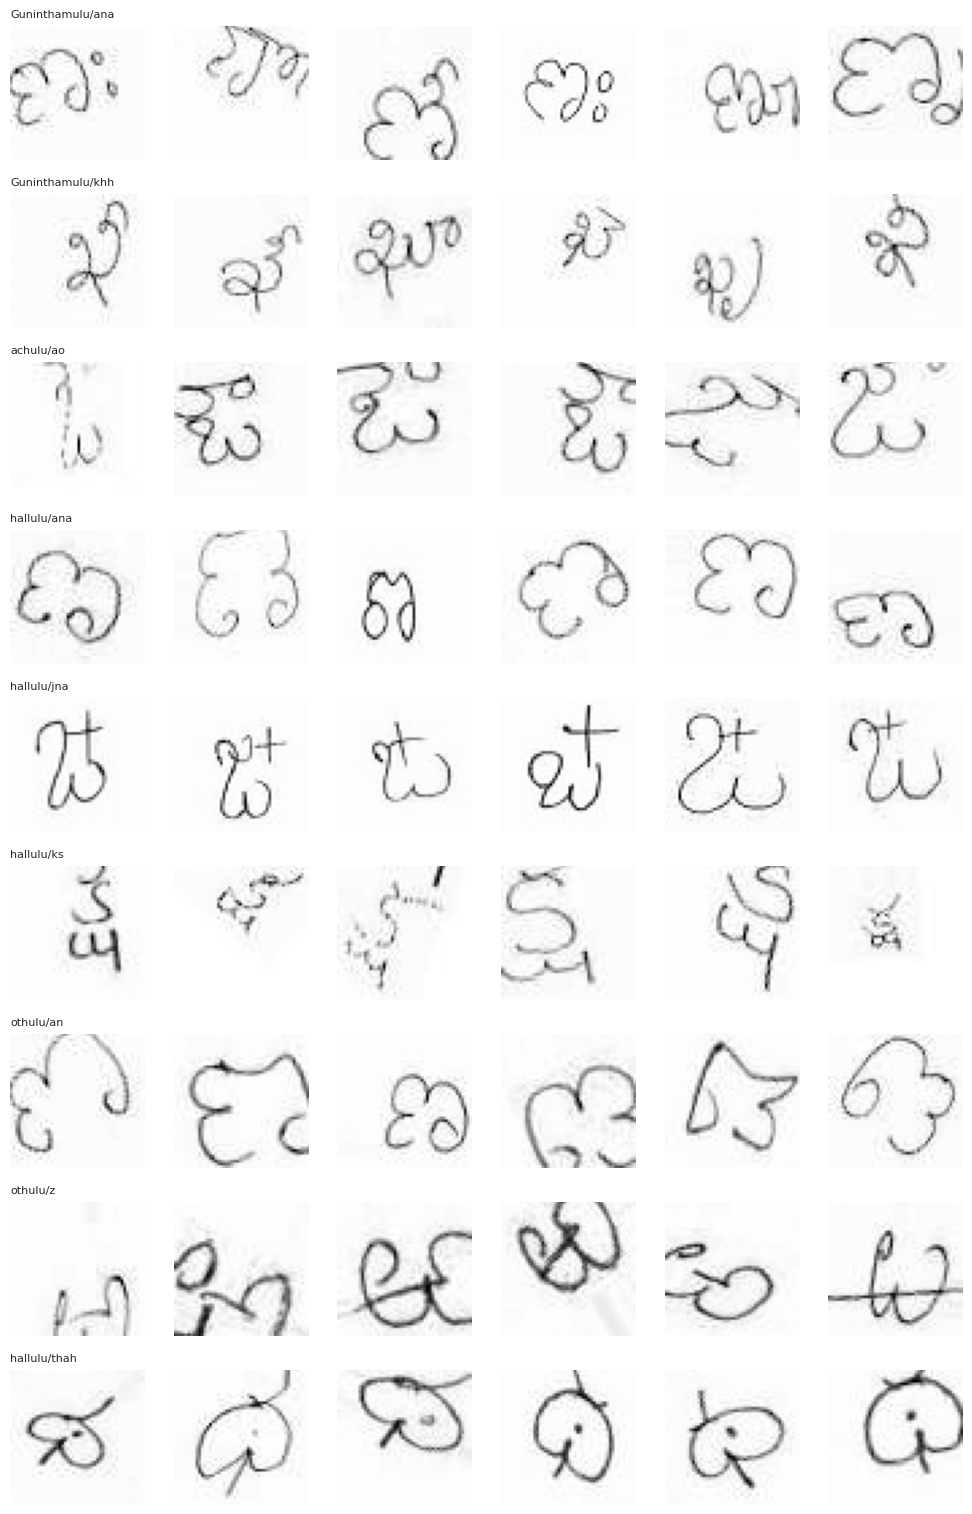

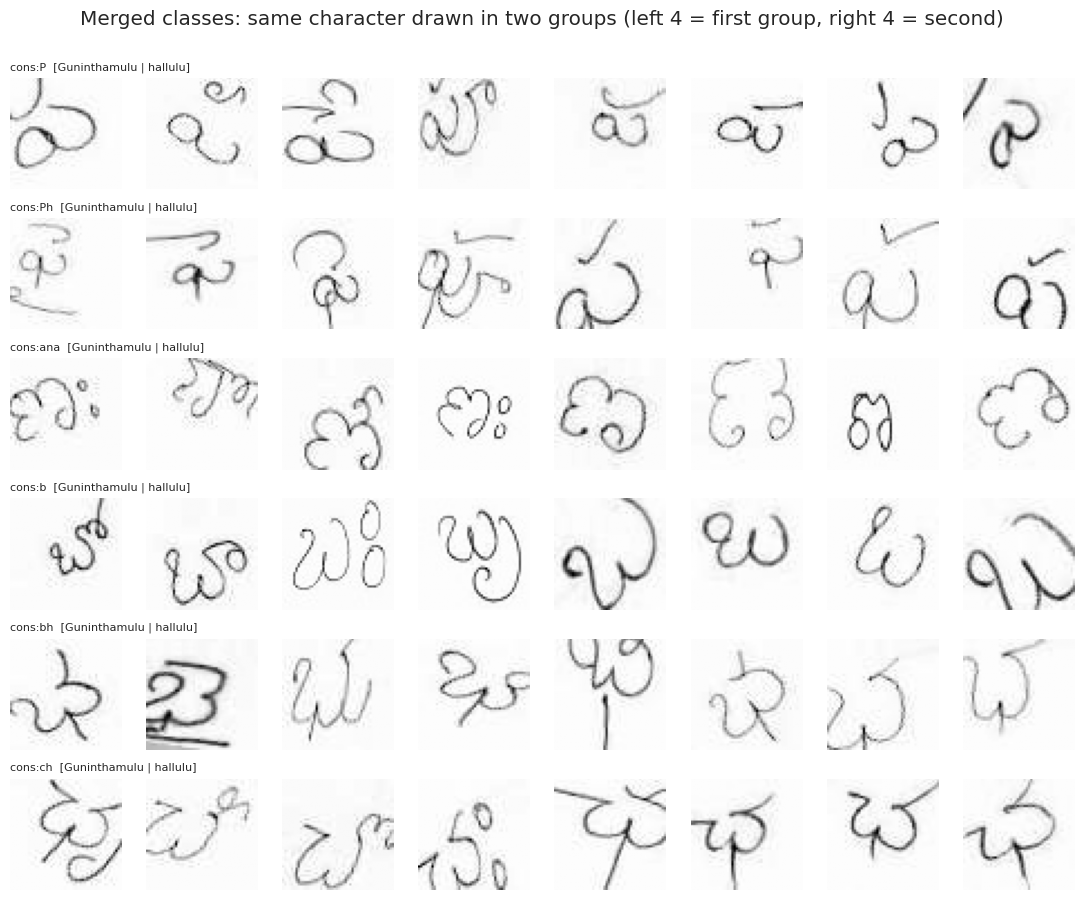

In [5]:
# Put manual fixes here, keyed by "<group>/<folder name>", e.g. {"hallulu/ta": "ట"}
# othulu (conjunct subscripts) are stored as VIRAMA + consonant, matching resolve_unicode() output.
MANUAL_UNICODE = {
    "Guninthamulu/ana": "ఙ",            # ṅa
    "Guninthamulu/khh": "ఖ",            # kha (typo-style folder name)
    "achulu/ao":        "ఔ",            # au -- no separate 'au' folder exists, 'ao' sits in its place
    "hallulu/ana":      "ఙ",            # ṅa
    "hallulu/jna":      "ఞ",            # ña
    "hallulu/ks":       "క్ష",           # kṣa conjunct
    "othulu/an":        VIRAMA + "ఙ",   # ్ఙ
    "othulu/z":         VIRAMA + "ళ",   # ్ళ  (LOW confidence -- verify against sample images below)
}

RAW_KEYS = sorted(df["key"].unique())
RAW_KEY2UNI, unresolved = {}, []
for k in RAW_KEYS:
    g, sub = k.split("/", 1)
    u, ok = resolve_unicode(sub, g)
    u = MANUAL_UNICODE.get(k, u)
    RAW_KEY2UNI[k] = u
    if not ok and k not in MANUAL_UNICODE: unresolved.append(k)
print(f"Resolved {len(RAW_KEYS) - len(unresolved)}/{len(RAW_KEYS)} folder names to Telugu Unicode.")
if unresolved: print("Unresolved (add to MANUAL_UNICODE):", unresolved[:40])

# ---- which folders are the SAME character? -------------------------------------------------
_u = pd.Series(RAW_KEY2UNI, name="unicode").rename_axis("key").reset_index()
_dup = _u.groupby("unicode")["key"].apply(list)
_dup = _dup[_dup.str.len() > 1]
print(f"\n{len(_dup)} Telugu characters are spread over several folders" + (" -> merged into ONE class each:" if MERGE_BY_UNICODE else " (MERGE_BY_UNICODE=False, NOT merged):"))
print(_dup.to_string())

# ---- final classes ---------------------------------------------------------------------------
TYPE_OF = {"Guninthamulu": "cons", "hallulu": "cons", "achulu": "vowel", "othulu": "sub"}
df["uni"]      = df["key"].map(RAW_KEY2UNI)
df["sub_type"] = df["group"].map(TYPE_OF).fillna("other")
df["cls"]      = df["uni"] if MERGE_BY_UNICODE else df["key"]
names = {}
for c, sub in df.groupby("cls"):
    pref = sub[sub["group"].isin(["hallulu", "achulu", "othulu"])]          # prefer the hand-written group's folder spelling
    src_ = pref if len(pref) else sub
    names[c] = f"{sub['sub_type'].iloc[0]}:{src_['sub'].value_counts().index[0]}"
_seen = Counter(names.values())
for c, n in list(names.items()):
    if _seen[n] > 1: names[c] = n + "_" + "".join(f"{ord(ch):x}" for ch in df.loc[df["cls"] == c, "uni"].iloc[0])
order = sorted(names, key=lambda c: names[c])
CLS2IDX    = {c: i for i, c in enumerate(order)}
CLASS_KEYS = [names[c] for c in order]
KEY2IDX    = {k: i for i, k in enumerate(CLASS_KEYS)}
df["label"] = df["cls"].map(CLS2IDX)
IDX2UNI = {i: df.loc[df["cls"] == c, "uni"].iloc[0] for c, i in CLS2IDX.items()}
NUM_CLASSES = len(CLASS_KEYS)

# ---- balance: cap images per (class, source group) ------------------------------------------
BEFORE_COUNTS = df["label"].value_counts().reindex(range(NUM_CLASSES)).fillna(0).astype(int)
df = df.sample(frac=1, random_state=SEED).reset_index(drop=True)                    # shuffle, then keep the first N of each (class, group)
df = df[df.groupby(["label", "group"]).cumcount() < MAX_PER_GROUP_CLASS].reset_index(drop=True)
if QUICK_TEST:
    df = df[df.groupby("label").cumcount() < 30].reset_index(drop=True)
AFTER_COUNTS = df["label"].value_counts().reindex(range(NUM_CLASSES)).fillna(0).astype(int)
print(f"\nClasses used: {NUM_CLASSES}  (raw folders: {len(RAW_KEYS)})")
print(f"images before balancing: {BEFORE_COUNTS.sum()}  | per-class min/median/max = {BEFORE_COUNTS.min()}/{int(BEFORE_COUNTS.median())}/{BEFORE_COUNTS.max()}  (max/min = {BEFORE_COUNTS.max()/max(BEFORE_COUNTS.min(),1):.0f}x)")
print(f"images after  balancing: {AFTER_COUNTS.sum()}  | per-class min/median/max = {AFTER_COUNTS.min()}/{int(AFTER_COUNTS.median())}/{AFTER_COUNTS.max()}  (max/min = {AFTER_COUNTS.max()/max(AFTER_COUNTS.min(),1):.0f}x)")
print("   (the remaining imbalance is handled by the class-balanced sampler in section 6)")

map_df = pd.DataFrame({"idx": list(IDX2UNI), "class_key": CLASS_KEYS, "unicode": [IDX2UNI[i] for i in IDX2UNI],
                       "n_before": BEFORE_COUNTS.values, "n_after": AFTER_COUNTS.values})
display(map_df.sample(min(15, len(map_df)), random_state=1).sort_values("idx"))
map_df.to_csv(os.path.join(REP_DIR, "class_unicode_mapping.csv"), index=False, encoding="utf-8")

# ---- sanity checks -------------------------------------------------------------------
still_bad = [k for k, u in IDX2UNI.items() if not TELUGU_RE.search(u)]
print("Classes still without Telugu characters:", [CLASS_KEYS[i] for i in still_bad] or "none")
_d2 = pd.Series(IDX2UNI).value_counts()
print("Classes sharing a Unicode string after merging:", list(_d2[_d2 > 1].index) or "none")

# ---- eyeball: (a) manual / suspicious folders, (b) merged twins from different groups -----------------
_suspect = [k for k, u in RAW_KEY2UNI.items() if not k.startswith("achulu") and ("\u0C02" in u or "\u0C03" in u)]   # e.g. hallulu/thah -> థః
_chk = [k for k in dict.fromkeys(list(MANUAL_UNICODE) + _suspect) if k in set(RAW_KEYS)]
if _chk:
    fig, axes = plt.subplots(len(_chk), 6, figsize=(10, 1.7 * len(_chk)), squeeze=False)
    for r, k in enumerate(_chk):
        print(f"{k:20s} -> {RAW_KEY2UNI[k]}" + ("   <-- auto-resolved, please verify" if k in _suspect and k not in MANUAL_UNICODE else ""))
        for c_, p in enumerate(df[df["key"] == k]["path"].head(6)):
            axes[r, c_].imshow(load_image_gray(p), cmap="gray")
        for a_ in axes[r]: a_.axis("off")
        axes[r, 0].set_title(k, fontsize=8, loc="left")
    plt.tight_layout(); plt.show()

_tw = [c for c in order if df.loc[df["cls"] == c, "group"].nunique() > 1 and df.loc[df["cls"] == c, "sub_type"].iloc[0] == "cons"][:6]
if _tw:
    fig, axes = plt.subplots(len(_tw), 8, figsize=(11, 1.5 * len(_tw)), squeeze=False)
    for r, c in enumerate(_tw):
        sub = df[df["cls"] == c]
        gs = sorted(sub["group"].unique())[:2]
        for gi, g in enumerate(gs):
            for j, p in enumerate(sub[sub["group"] == g]["path"].head(4)):
                axes[r, gi * 4 + j].imshow(load_image_gray(p), cmap="gray")
        for a_ in axes[r]: a_.axis("off")
        axes[r, 0].set_title(f"{names[c]}  [{' | '.join(gs)}]", fontsize=8, loc="left")
    plt.suptitle("Merged classes: same character drawn in two groups (left 4 = first group, right 4 = second)", y=1.0)
    plt.tight_layout(); plt.show()


## 4. Exploratory data analysis

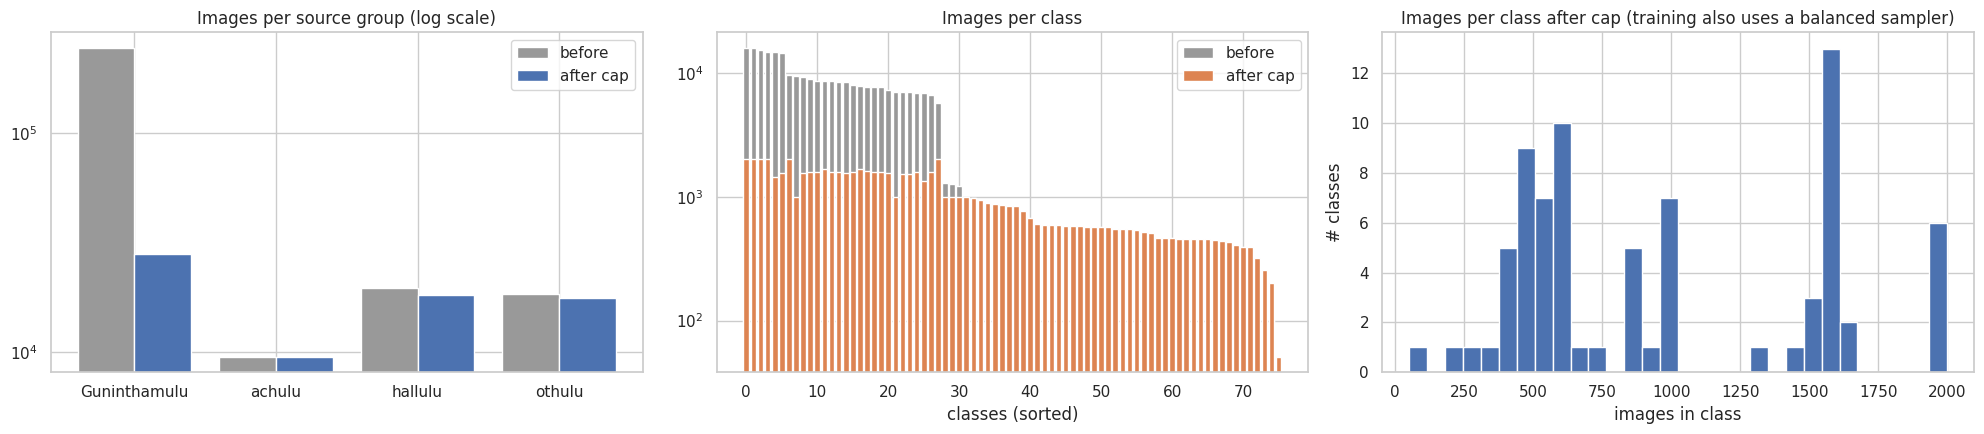

count      76.0
mean      966.6
std       550.7
min        51.0
25%       517.2
50%       843.5
75%      1562.0
max      2000.0


In [6]:
fig, ax = plt.subplots(1, 3, figsize=(20, 4.5))
g_before = RAW_GROUP_COUNTS.reindex(GROUPS).fillna(0); g_after = df["group"].value_counts().reindex(GROUPS).fillna(0)
xg = np.arange(len(GROUPS)); w = 0.4
ax[0].bar(xg - w/2, g_before.values, w, label="before", color="#999999"); ax[0].bar(xg + w/2, g_after.values, w, label="after cap", color="#4C72B0")
ax[0].set_xticks(xg); ax[0].set_xticklabels(GROUPS); ax[0].set_yscale("log"); ax[0].set_title("Images per source group (log scale)"); ax[0].legend()
order_ = BEFORE_COUNTS.sort_values(ascending=False).index
ax[1].bar(range(NUM_CLASSES), BEFORE_COUNTS.reindex(order_).values, color="#999999", label="before")
ax[1].bar(range(NUM_CLASSES), AFTER_COUNTS.reindex(order_).values, color="#DD8452", label="after cap")
ax[1].set_yscale("log"); ax[1].set_xlabel("classes (sorted)"); ax[1].set_title("Images per class"); ax[1].legend()
ax[2].hist(AFTER_COUNTS.values, bins=30, color="#4C72B0"); ax[2].set_title("Images per class after cap (training also uses a balanced sampler)")
ax[2].set_xlabel("images in class"); ax[2].set_ylabel("# classes")
savefig("01_dataset_distribution.png")
print(AFTER_COUNTS.describe().round(1).to_string())


## 5. Image preprocessing — CLAHE + noise removal

In [7]:
def _load_and_prep(path):
    raw = load_image_gray(path)
    if raw is None: return None
    return preprocess_gray(raw, IMG_SIZE)

t0 = time.time()
with ThreadPoolExecutor(max_workers=8) as ex:
    imgs = list(tqdm(ex.map(_load_and_prep, df["path"].tolist()), total=len(df), desc="preprocessing"))
ok_mask = np.array([im is not None for im in imgs])
print(f"unreadable images dropped: {(~ok_mask).sum()} | time: {time.time()-t0:.1f}s")
df = df[ok_mask].reset_index(drop=True)
X = np.stack([im for im in imgs if im is not None]).astype(np.uint8)   # (N, S, S)
y = df["label"].values.astype(np.int64)
del imgs
print("X:", X.shape, X.dtype, "| y:", y.shape, "| classes:", len(np.unique(y)))

preprocessing:   0%|          | 0/73463 [00:00<?, ?it/s]

unreadable images dropped: 0 | time: 426.3s
X: (73463, 96, 96) uint8 | y: (73463,) | classes: 76


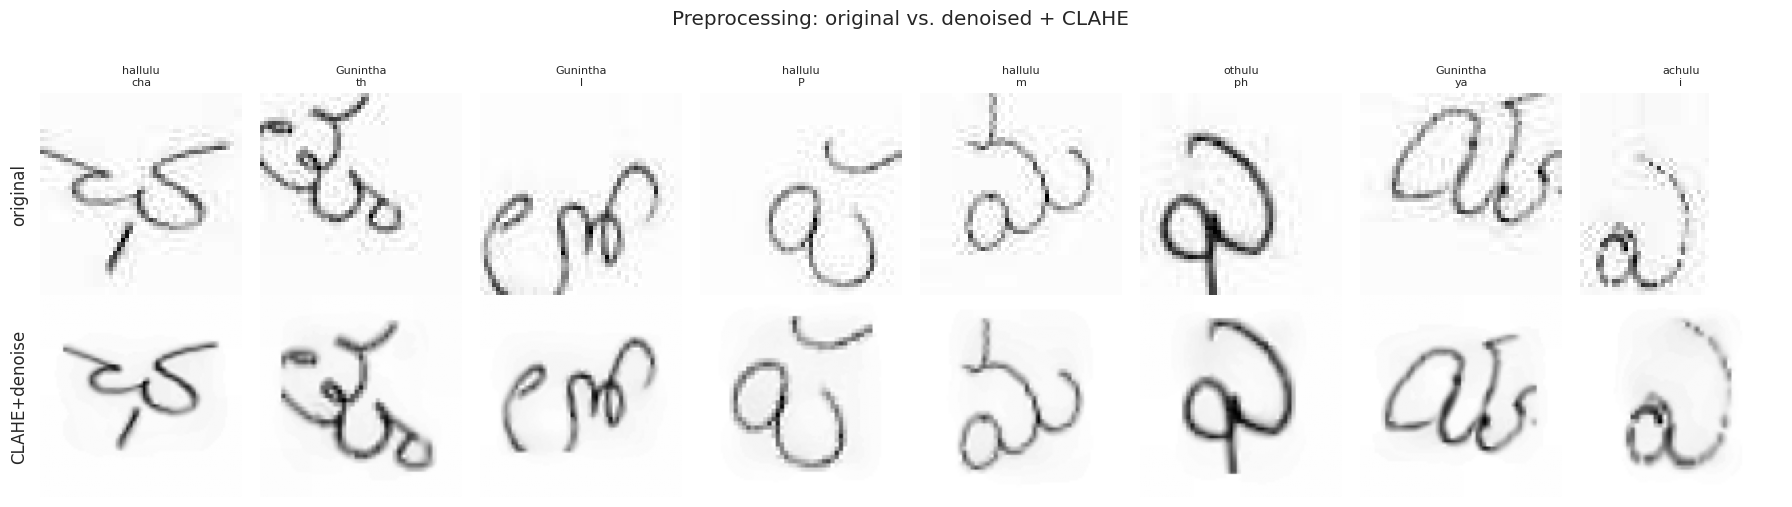

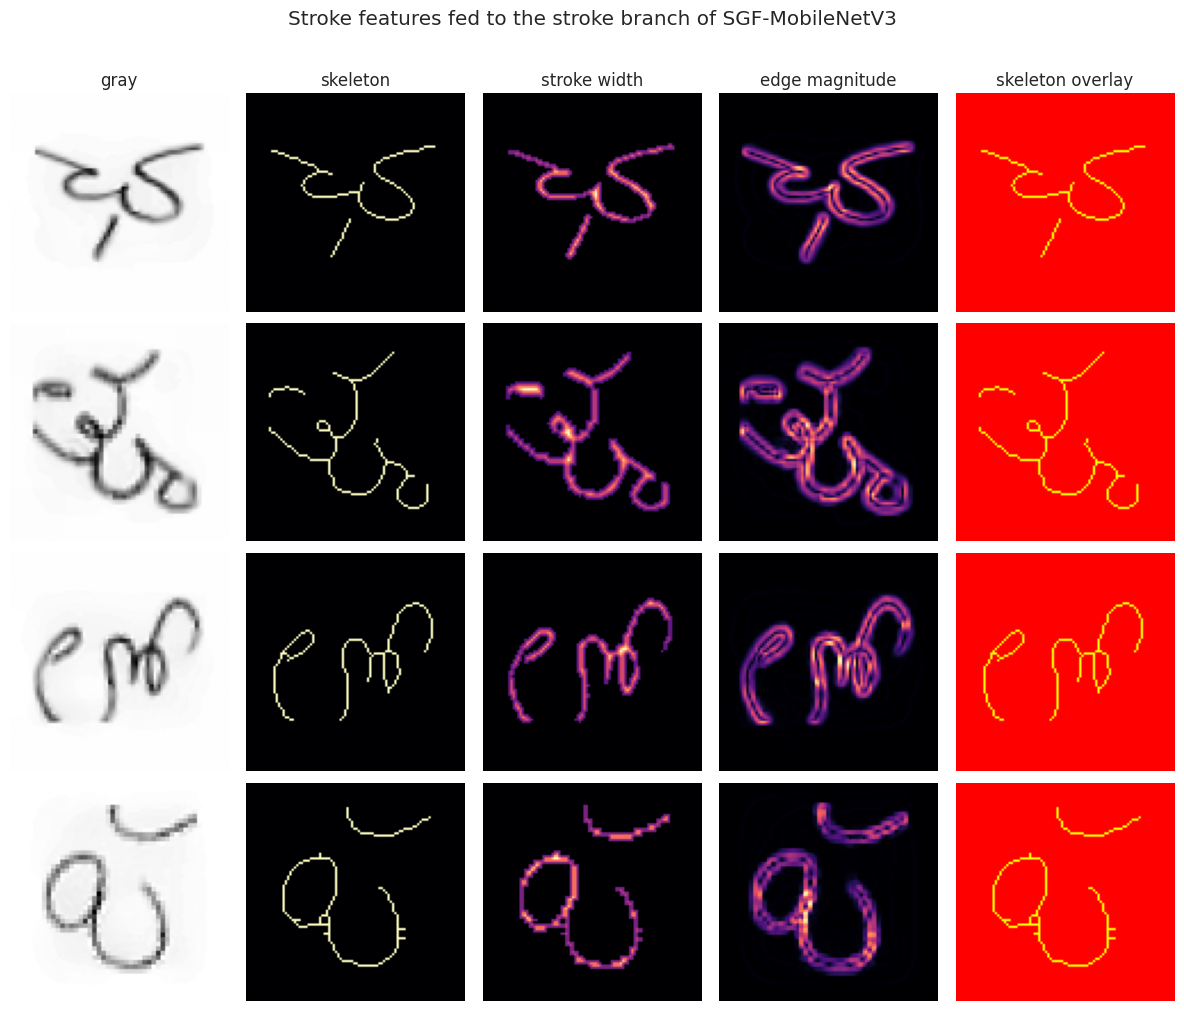

In [8]:
# before / after preprocessing
rng = np.random.default_rng(0)
pick = rng.choice(len(df), 8, replace=False)
fig, axes = plt.subplots(2, 8, figsize=(18, 5))
for j, i in enumerate(pick):
    raw = load_image_gray(df["path"].iloc[i])
    axes[0, j].imshow(raw, cmap="gray"); axes[0, j].set_title(df["key"].iloc[i].split("/")[0][:8] + "\n" + df["sub"].iloc[i][:10], fontsize=8)
    axes[1, j].imshow(X[i], cmap="gray")
    for a in axes[:, j]: a.axis("off")
axes[0, 0].text(-0.15, 0.5, "original", transform=axes[0, 0].transAxes, rotation=90, va="center")
axes[1, 0].text(-0.15, 0.5, "CLAHE+denoise", transform=axes[1, 0].transAxes, rotation=90, va="center")
plt.suptitle("Preprocessing: original vs. denoised + CLAHE", y=1.02)
savefig("02_preprocessing_before_after.png")

# stroke feature maps (used by Model 2)
fig, axes = plt.subplots(4, 5, figsize=(12, 10))
for r, i in enumerate(pick[:4]):
    s = compute_stroke_maps(X[i])
    for c, (im, t) in enumerate(zip([X[i], s[0], s[1], s[2], X[i]], ["gray", "skeleton", "stroke width", "edge magnitude", ""])):
        if c == 4:
            axes[r, c].imshow(X[i], cmap="gray"); axes[r, c].imshow(s[0], cmap="autumn", alpha=0.6 * (s[0] > 0)); t = "skeleton overlay"
        else:
            axes[r, c].imshow(im, cmap="gray" if c == 0 else "magma")
        axes[r, c].axis("off")
        if r == 0: axes[r, c].set_title(t)
plt.suptitle("Stroke features fed to the stroke branch of SGF-MobileNetV3", y=1.01)
savefig("03_stroke_features.png")

## 6. Train / validation / test split and data loaders
Stratified split, **stronger augmentation**, and a **class-balanced `WeightedRandomSampler`** for the training set (validation/test stay un-resampled so the metrics are honest).


In [9]:
idx_all = np.arange(len(y))
idx_trainval, idx_test = train_test_split(idx_all, test_size=TEST_FRAC, stratify=y, random_state=SEED)
idx_train, idx_val = train_test_split(idx_trainval, test_size=VAL_FRAC / (1 - TEST_FRAC),
                                      stratify=y[idx_trainval], random_state=SEED)
print(f"train {len(idx_train)} | val {len(idx_val)} | test {len(idx_test)}")
test_group = df["group"].values[idx_test]          # source group of every test sample (same order as test_loader)

def augment(g, rng):
    h, w = g.shape
    bg = int(np.percentile(g, 90))
    M = cv2.getRotationMatrix2D((w / 2, h / 2), rng.uniform(-10, 10), rng.uniform(0.80, 1.10))
    M[0, 1] += rng.uniform(-0.12, 0.12)                         # shear
    M[:, 2] += rng.uniform(-0.07, 0.07, 2) * w                  # shift
    out = cv2.warpAffine(g, M, (w, h), flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_CONSTANT, borderValue=bg)
    r = rng.random()
    if r < 0.15:   out = cv2.erode(out, np.ones((2, 2), np.uint8))     # thicker ink (dark strokes grow)
    elif r < 0.30: out = cv2.dilate(out, np.ones((2, 2), np.uint8))    # thinner ink
    if rng.random() < 0.25:                                            # low-resolution upload
        s_ = int(rng.integers(40, 72)); out = cv2.resize(cv2.resize(out, (s_, s_), interpolation=cv2.INTER_AREA), (w, h), interpolation=cv2.INTER_LINEAR)
    if rng.random() < 0.25: out = cv2.GaussianBlur(out, (3, 3), 0)
    if rng.random() < 0.30:                                            # contrast / brightness
        out = np.clip(out.astype(np.float32) * rng.uniform(0.8, 1.1) + rng.uniform(-15, 15), 0, 255).astype(np.uint8)
    return out

class TeluguDS(Dataset):
    # returns: gray image (1,H,W) in [0,1], stroke maps (3,H,W), label
    def __init__(self, X, y, train=False):
        self.X, self.y, self.train = X, y, train
    def __len__(self): return len(self.y)
    def __getitem__(self, i):
        g = self.X[i]
        if self.train: g = augment(g, np.random.default_rng())
        s = compute_stroke_maps(g)
        return torch.from_numpy(g).float().div_(255.).unsqueeze(0), torch.from_numpy(s), int(self.y[i])

# class-balanced sampling for the TRAIN split: every class is drawn about equally often
cls_counts = np.bincount(y[idx_train], minlength=NUM_CLASSES)
sample_w = (1.0 / np.maximum(cls_counts, 1) ** BALANCE_POWER)[y[idx_train]]
train_sampler = WeightedRandomSampler(torch.as_tensor(sample_w, dtype=torch.double), num_samples=len(idx_train), replacement=True)
_drawn = np.bincount(y[idx_train][np.fromiter(iter(train_sampler), dtype=np.int64)], minlength=NUM_CLASSES)
print(f"train images per class: min {cls_counts.min()} / max {cls_counts.max()}   ->   drawn per epoch: min {_drawn.min()} / max {_drawn.max()}")

def make_loader(idx, train):
    kw = dict(sampler=train_sampler) if train else dict(shuffle=False)
    return DataLoader(TeluguDS(X[idx], y[idx], train), batch_size=BATCH_SIZE, num_workers=NUM_WORKERS,
                      pin_memory=DEVICE.type == "cuda", persistent_workers=NUM_WORKERS > 0, drop_last=False, **kw)

train_loader, val_loader, test_loader = make_loader(idx_train, True), make_loader(idx_val, False), make_loader(idx_test, False)
xb, sb, yb = next(iter(train_loader)); print("batch shapes:", xb.shape, sb.shape, yb.shape)


train 51423 | val 11020 | test 11020
train images per class: min 35 / max 1400   ->   drawn per epoch: min 585 / max 725
batch shapes: torch.Size([64, 1, 96, 96]) torch.Size([64, 3, 96, 96]) torch.Size([64])


## 7. Models

**Model 1 – MobileNetV3-Small (baseline):** grayscale → 3-ch → **reduced-capacity** MobileNetV3-Small
(early feature stages only, ~96-d) → global pool → classifier. This keeps the same family as the proposed
model while using fewer parameters so the contribution of the stroke-gated branch is measurable.

**Model 2 – SGF-MobileNetV3 (proposed):** two branches
1. *Appearance branch* – full MobileNetV3-Small backbone (576-d).
2. *Stroke branch* – a light CNN on the stroke maps (skeleton / stroke width / edges) (128-d).
3. *Gated Feature Fusion* – a learned gate decides per-dimension how much to trust appearance vs stroke features:

   `g = σ(W·[f_app ‖ f_stroke])`, `f = g ⊙ f_app + (1−g) ⊙ f_stroke`

Only these two models are trained and compared.


In [10]:
IM_MEAN, IM_STD = 0.449, 0.226   # ImageNet gray-ish statistics

def build_backbone():
    weights = None
    if USE_PRETRAINED:
        try:
            weights = MobileNet_V3_Small_Weights.IMAGENET1K_V1
            m = mobilenet_v3_small(weights=weights)
            print("  loaded ImageNet-pretrained MobileNetV3-Small")
            return m
        except Exception as e:
            print("  [info] pretrained weights unavailable (", type(e).__name__, ") -> random init")
    return mobilenet_v3_small(weights=None)

def to_rgb(x):                      # (B,1,H,W) in [0,1] -> normalised (B,3,H,W)
    return ((x - IM_MEAN) / IM_STD).expand(-1, 3, -1, -1)

# ---------------------------------------------------------------------------
# BASELINE: reduced-capacity MobileNetV3-Small
# Keep only the early inverted-residual stages (features[:9] → 96 channels)
# so the parameter count and representational power are deliberately lower
# than the full backbone used inside the proposed SGF model.
# ---------------------------------------------------------------------------
class BaselineMNV3(nn.Module):
    def __init__(self, n_classes):
        super().__init__()
        m = build_backbone()
        # Truncate to early stages only (MobileNetV3-Small features[0..8] → 96-d)
        self.features = nn.Sequential(*list(m.features.children())[:9])
        self.pool = nn.AdaptiveAvgPool2d(1)
        with torch.no_grad():
            dummy = torch.zeros(1, 3, IMG_SIZE, IMG_SIZE)
            feat_dim = self.features(dummy).shape[1]
        self.feat_dim = feat_dim
        self.head = nn.Sequential(
            nn.Dropout(0.35),                    # slightly stronger regularisation
            nn.Linear(feat_dim, n_classes)
        )
    def forward(self, x, s=None, return_gate=False):
        f = self.pool(self.features(to_rgb(x))).flatten(1)
        return self.head(f)

class StrokeBranch(nn.Module):
    def __init__(self, out_dim=128):
        super().__init__()
        def blk(i, o): return nn.Sequential(nn.Conv2d(i, o, 3, 2, 1, bias=False), nn.BatchNorm2d(o), nn.ReLU(inplace=True))
        self.net = nn.Sequential(blk(3, 16), blk(16, 32), blk(32, 64), blk(64, out_dim), nn.AdaptiveAvgPool2d(1))
    def forward(self, s): return self.net(s).flatten(1)

# ---------------------------------------------------------------------------
# PROPOSED: full MobileNetV3-Small + stroke branch + gated fusion
# ---------------------------------------------------------------------------
class SGFMobileNetV3(nn.Module):
    def __init__(self, n_classes, fused_dim=256):
        super().__init__()
        m = build_backbone()
        self.features, self.pool = m.features, nn.AdaptiveAvgPool2d(1)   # full 576-d backbone
        self.stroke = StrokeBranch(128)
        self.proj_app    = nn.Sequential(nn.Linear(576, fused_dim), nn.BatchNorm1d(fused_dim), nn.ReLU(inplace=True))
        self.proj_stroke = nn.Sequential(nn.Linear(128, fused_dim), nn.BatchNorm1d(fused_dim), nn.ReLU(inplace=True))
        self.gate = nn.Sequential(nn.Linear(576 + 128, fused_dim), nn.Sigmoid())
        self.head = nn.Sequential(nn.Dropout(0.2), nn.Linear(fused_dim, n_classes))
    def forward(self, x, s, return_gate=False):
        fa = self.pool(self.features(to_rgb(x))).flatten(1)
        fs = self.stroke(s)
        g = self.gate(torch.cat([fa, fs], 1))
        fused = g * self.proj_app(fa) + (1 - g) * self.proj_stroke(fs)
        logits = self.head(fused)
        return (logits, g) if return_gate else logits

def count_params(m): return sum(p.numel() for p in m.parameters())

MODEL_SPECS = {
    "Model1_MobileNetV3Small_Baseline": dict(cls=BaselineMNV3, uses_stroke=False, short="Baseline"),
    "Model2_SGF_MobileNetV3_Proposed":  dict(cls=SGFMobileNetV3, uses_stroke=True,  short="SGF-MobileNetV3"),
}
for name, sp in MODEL_SPECS.items():
    print(f"{name:38s} params: {count_params(sp['cls'](NUM_CLASSES))/1e6:.2f} M")


Downloading: "https://download.pytorch.org/models/mobilenet_v3_small-047dcff4.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_small-047dcff4.pth


100%|██████████| 9.83M/9.83M [00:00<00:00, 49.7MB/s]


  loaded ImageNet-pretrained MobileNetV3-Small
Model1_MobileNetV3Small_Baseline       params: 0.19 M
  loaded ImageNet-pretrained MobileNetV3-Small
Model2_SGF_MobileNetV3_Proposed        params: 1.41 M


## 8. Training loop (AdamW + OneCycle LR + label smoothing + AMP + early stopping)

In [11]:
USE_AMP = DEVICE.type == "cuda"

def fwd(model, x, s, uses_stroke):
    return model(x, s) if uses_stroke else model(x)

def run_epoch(model, loader, uses_stroke, criterion, optimizer=None, scheduler=None, scaler=None):
    train = optimizer is not None
    model.train(train)
    tot_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(train):
        for x, s, yb in loader:
            x, s, yb = x.to(DEVICE, non_blocking=True), s.to(DEVICE, non_blocking=True), yb.to(DEVICE, non_blocking=True)
            with torch.autocast(device_type=DEVICE.type, enabled=USE_AMP):
                out = fwd(model, x, s, uses_stroke)
                loss = criterion(out, yb)
            if train:
                optimizer.zero_grad(set_to_none=True)
                scaler.scale(loss).backward(); scaler.step(optimizer); scaler.update()
                if scheduler is not None: scheduler.step()
            tot_loss += loss.item() * len(yb); correct += (out.argmax(1) == yb).sum().item(); n += len(yb)
    return tot_loss / n, correct / n

def train_model(name, spec):
    seed_everything(SEED)
    print(f"\n=== Training {name} ===")
    model = spec["cls"](NUM_CLASSES).to(DEVICE)
    criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
    optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    scheduler = torch.optim.lr_scheduler.OneCycleLR(optimizer, max_lr=LR, epochs=EPOCHS,
                                                    steps_per_epoch=len(train_loader), pct_start=0.15)
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
    hist, best = [], dict(acc=-1, loss=1e9, state=None, epoch=0)
    bad = 0; t0 = time.time()
    for ep in range(1, EPOCHS + 1):
        tr_loss, tr_acc = run_epoch(model, train_loader, spec["uses_stroke"], criterion, optimizer, scheduler, scaler)
        va_loss, va_acc = run_epoch(model, val_loader, spec["uses_stroke"], criterion)
        hist.append(dict(epoch=ep, train_loss=tr_loss, train_acc=tr_acc, val_loss=va_loss, val_acc=va_acc,
                         lr=optimizer.param_groups[0]["lr"]))
        improved = (va_acc > best["acc"]) or (va_acc == best["acc"] and va_loss < best["loss"])
        if improved:
            best.update(acc=va_acc, loss=va_loss, epoch=ep, state=copy.deepcopy(model.state_dict())); bad = 0
        else:
            bad += 1
        print(f"ep {ep:02d}/{EPOCHS} | train {tr_loss:.3f}/{tr_acc:.3f} | val {va_loss:.3f}/{va_acc:.3f}" + (" *" if improved else ""))
        if bad >= PATIENCE:
            print(f"early stopping at epoch {ep} (best epoch {best['epoch']})"); break
    model.load_state_dict(best["state"])
    train_time = time.time() - t0
    print(f"best val acc {best['acc']:.4f} @ epoch {best['epoch']} | train time {train_time/60:.1f} min")
    return model, pd.DataFrame(hist), dict(best_epoch=best["epoch"], best_val_acc=best["acc"], train_time_s=train_time)

MODELS, HISTORY, TRAIN_INFO = {}, {}, {}
for name, spec in MODEL_SPECS.items():
    MODELS[name], HISTORY[name], TRAIN_INFO[name] = train_model(name, spec)
    HISTORY[name].to_csv(os.path.join(REP_DIR, f"history_{name}.csv"), index=False)
    # checkpoint immediately so nothing is lost if the session dies
    torch.save(MODELS[name].state_dict(), os.path.join(MODEL_DIR, f"{name}.pth"))


=== Training Model1_MobileNetV3Small_Baseline ===
  loaded ImageNet-pretrained MobileNetV3-Small
ep 01/30 | train 4.228/0.040 | val 4.030/0.072 *
ep 02/30 | train 3.202/0.265 | val 2.940/0.299 *
ep 03/30 | train 2.188/0.555 | val 2.084/0.564 *
ep 04/30 | train 1.812/0.681 | val 1.738/0.683 *
ep 05/30 | train 1.604/0.753 | val 1.598/0.729 *
ep 06/30 | train 1.501/0.788 | val 1.487/0.769 *
ep 07/30 | train 1.414/0.818 | val 1.409/0.793 *
ep 08/30 | train 1.356/0.839 | val 1.359/0.809 *
ep 09/30 | train 1.320/0.848 | val 1.302/0.830 *
ep 10/30 | train 1.284/0.861 | val 1.256/0.844 *
ep 11/30 | train 1.254/0.873 | val 1.266/0.839
ep 12/30 | train 1.231/0.877 | val 1.261/0.839
ep 13/30 | train 1.207/0.888 | val 1.186/0.868 *
ep 14/30 | train 1.190/0.893 | val 1.161/0.879 *
ep 15/30 | train 1.170/0.898 | val 1.141/0.885 *
ep 16/30 | train 1.153/0.904 | val 1.125/0.887 *
ep 17/30 | train 1.136/0.910 | val 1.110/0.894 *
ep 18/30 | train 1.122/0.915 | val 1.098/0.898 *
ep 19/30 | train 1.110/0

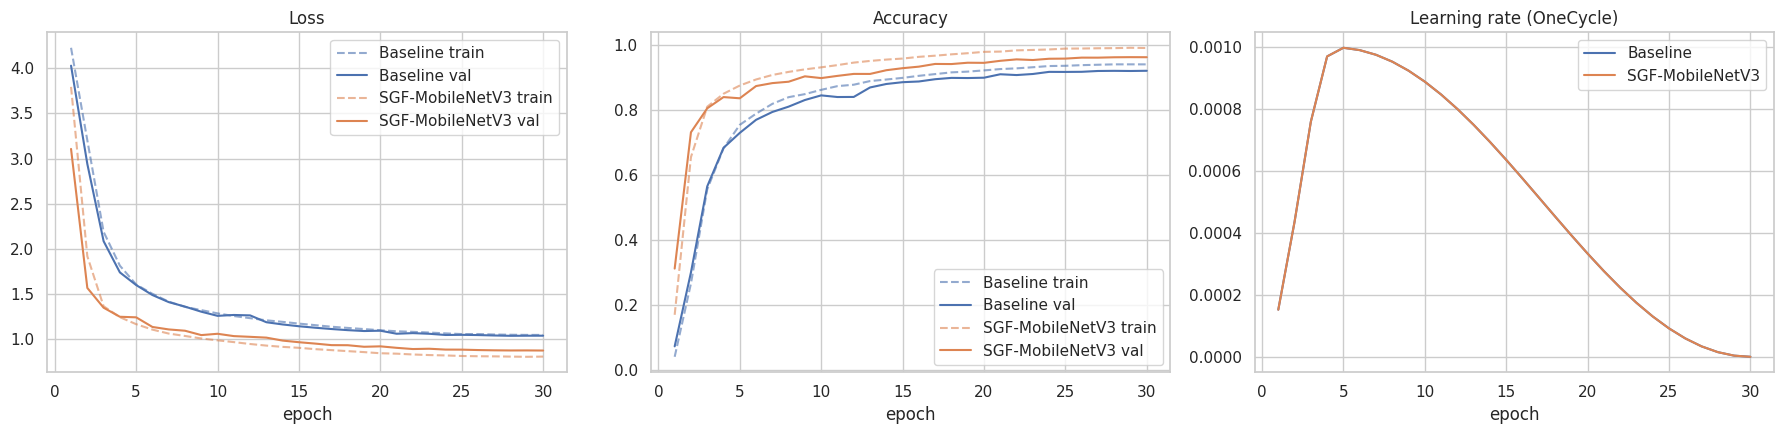

In [12]:
# training curves
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
colors = {"Model1_MobileNetV3Small_Baseline": "#4C72B0", "Model2_SGF_MobileNetV3_Proposed": "#DD8452"}
for name, h in HISTORY.items():
    short = MODEL_SPECS[name]["short"]; c = colors[name]
    axes[0].plot(h["epoch"], h["train_loss"], "--", c=c, alpha=.6, label=f"{short} train"); axes[0].plot(h["epoch"], h["val_loss"], c=c, label=f"{short} val")
    axes[1].plot(h["epoch"], h["train_acc"], "--", c=c, alpha=.6, label=f"{short} train"); axes[1].plot(h["epoch"], h["val_acc"], c=c, label=f"{short} val")
    axes[2].plot(h["epoch"], h["lr"], c=c, label=short)
axes[0].set_title("Loss"); axes[1].set_title("Accuracy"); axes[2].set_title("Learning rate (OneCycle)")
for a in axes: a.set_xlabel("epoch"); a.legend()
savefig("04_training_curves.png")

## 9. Evaluation on the held-out test set

In [13]:
@torch.no_grad()
def predict(model, loader, uses_stroke):
    model.eval(); ys, ps, gates = [], [], []
    for x, s, yb in loader:
        x, s = x.to(DEVICE), s.to(DEVICE)
        with torch.autocast(device_type=DEVICE.type, enabled=USE_AMP):
            if uses_stroke:
                out, g = model(x, s, return_gate=True); gates.append(g.float().mean(1).cpu().numpy())
            else:
                out = model(x)
        ps.append(F.softmax(out.float(), 1).cpu().numpy()); ys.append(yb.numpy())
    return np.concatenate(ys), np.concatenate(ps), (np.concatenate(gates) if gates else None)

def compute_metrics(y_true, probs):
    y_pred = probs.argmax(1)
    pm, rm, fm, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
    pw, rw, fw, _ = precision_recall_fscore_support(y_true, y_pred, average="weighted", zero_division=0)
    top3 = np.mean([t in row for t, row in zip(y_true, np.argsort(-probs, 1)[:, :3])])
    return dict(accuracy=accuracy_score(y_true, y_pred), top3_accuracy=top3,
                precision_macro=pm, recall_macro=rm, f1_macro=fm,
                precision_weighted=pw, recall_weighted=rw, f1_weighted=fw)

RESULTS, PRED = {}, {}
for name, spec in MODEL_SPECS.items():
    yt, pr, gt = predict(MODELS[name], test_loader, spec["uses_stroke"])
    PRED[name] = dict(y_true=yt, probs=pr, y_pred=pr.argmax(1), gate=gt)
    RESULTS[name] = compute_metrics(yt, pr)
    print(f"\n{name}"); print({k: round(v, 4) for k, v in RESULTS[name].items()})

metrics_df = pd.DataFrame(RESULTS).T
display(metrics_df.round(4))


Model1_MobileNetV3Small_Baseline
{'accuracy': 0.9074, 'top3_accuracy': np.float64(0.9861), 'precision_macro': 0.8997, 'recall_macro': 0.9231, 'f1_macro': 0.9069, 'precision_weighted': 0.9165, 'recall_weighted': 0.9074, 'f1_weighted': 0.9089}

Model2_SGF_MobileNetV3_Proposed
{'accuracy': 0.959, 'top3_accuracy': np.float64(0.9948), 'precision_macro': 0.9533, 'recall_macro': 0.9571, 'f1_macro': 0.9534, 'precision_weighted': 0.9598, 'recall_weighted': 0.959, 'f1_weighted': 0.9589}


,accuracy,top3_accuracy,precision_macro,recall_macro,f1_macro,precision_weighted,recall_weighted,f1_weighted
Model1_MobileNetV3Small_Baseline,0.9074,0.9861,0.8997,0.9231,0.9069,0.9165,0.9074,0.9089
Model2_SGF_MobileNetV3_Proposed,0.9590,0.9948,0.9533,0.9571,0.9534,0.9598,0.9590,0.9589


saved classification report: Model1_MobileNetV3Small_Baseline
saved classification report: Model2_SGF_MobileNetV3_Proposed


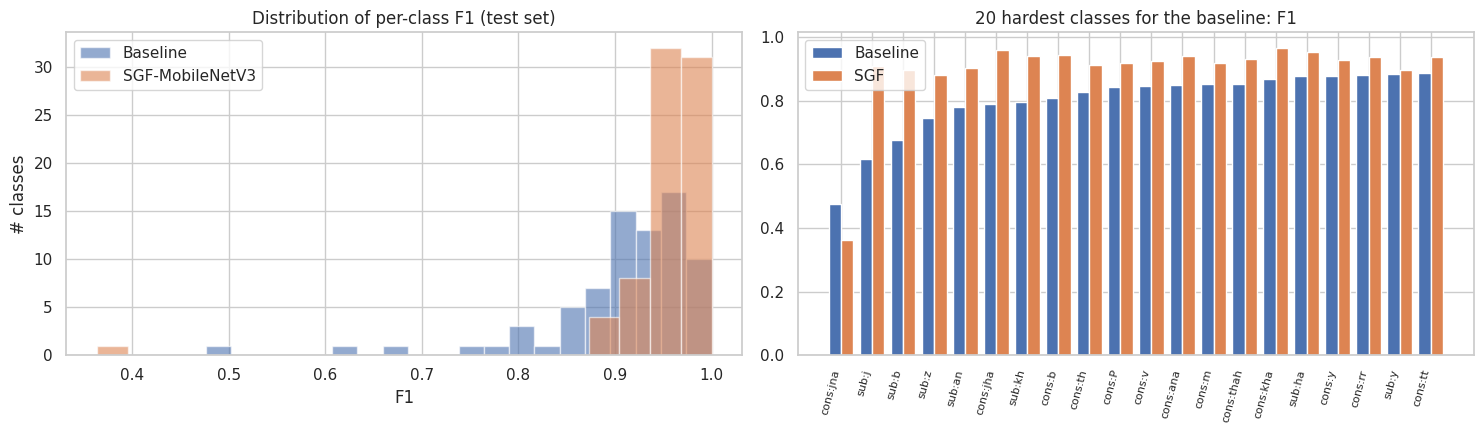

In [14]:
# per-model classification reports (saved) + per-class F1
SHORT_NAMES = [k.replace("/", "_") for k in CLASS_KEYS]
PERCLASS = {}
for name in MODEL_SPECS:
    rep = classification_report(PRED[name]["y_true"], PRED[name]["y_pred"], labels=list(range(NUM_CLASSES)),
                                target_names=SHORT_NAMES, output_dict=True, zero_division=0)
    rdf = pd.DataFrame(rep).T
    rdf.to_csv(os.path.join(REP_DIR, f"classification_report_{name}.csv"))
    PERCLASS[name] = rdf.iloc[:NUM_CLASSES]
    print(f"saved classification report: {name}")

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for name in MODEL_SPECS:
    axes[0].hist(PERCLASS[name]["f1-score"], bins=20, alpha=.6, label=MODEL_SPECS[name]["short"], color=colors[name])
axes[0].set_title("Distribution of per-class F1 (test set)"); axes[0].set_xlabel("F1"); axes[0].set_ylabel("# classes"); axes[0].legend()
# 20 hardest classes for the baseline, and how SGF does on them
hard = PERCLASS["Model1_MobileNetV3Small_Baseline"]["f1-score"].sort_values().head(20).index
w = 0.4; xs = np.arange(len(hard))
axes[1].bar(xs - w/2, PERCLASS["Model1_MobileNetV3Small_Baseline"].loc[hard, "f1-score"], w, label="Baseline", color=colors["Model1_MobileNetV3Small_Baseline"])
axes[1].bar(xs + w/2, PERCLASS["Model2_SGF_MobileNetV3_Proposed"].loc[hard, "f1-score"], w, label="SGF", color=colors["Model2_SGF_MobileNetV3_Proposed"])
axes[1].set_xticks(xs); axes[1].set_xticklabels(hard, rotation=75, ha="right", fontsize=8); axes[1].set_title("20 hardest classes for the baseline: F1"); axes[1].legend()
savefig("05_per_class_f1.png")

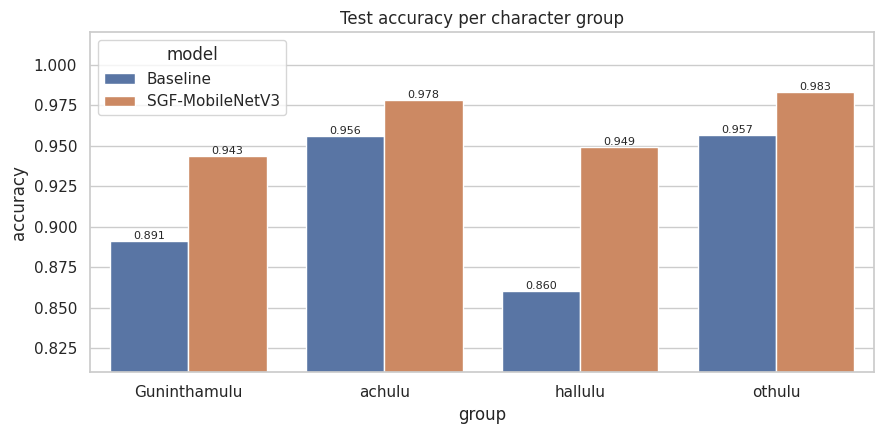

model,Baseline,SGF-MobileNetV3
group,,
Guninthamulu,0.8911,0.9434
achulu,0.9560,0.9784
hallulu,0.8602,0.9491
othulu,0.9566,0.9834


In [15]:
# accuracy per character group (Guninthamulu / achulu / hallulu / othulu)
# group of each test sample (classes are merged across groups now, so it is looked up per image)
grp_rows = []
for name in MODEL_SPECS:
    yt, yp = PRED[name]["y_true"], PRED[name]["y_pred"]
    for g in GROUPS:
        m = test_group == g
        if m.sum(): grp_rows.append(dict(model=MODEL_SPECS[name]["short"], group=g, accuracy=(yt[m] == yp[m]).mean(), n=int(m.sum())))
grp_df = pd.DataFrame(grp_rows); grp_df.to_csv(os.path.join(REP_DIR, "accuracy_per_group.csv"), index=False)
plt.figure(figsize=(9, 4.5))
ax = sns.barplot(data=grp_df, x="group", y="accuracy", hue="model", palette=[colors[n] for n in MODEL_SPECS])
for c in ax.containers: ax.bar_label(c, fmt="%.3f", fontsize=8)
plt.ylim(max(0, grp_df["accuracy"].min() - 0.05), 1.02); plt.title("Test accuracy per character group")
savefig("06_accuracy_per_group.png")
display(grp_df.pivot(index="group", columns="model", values="accuracy").round(4))

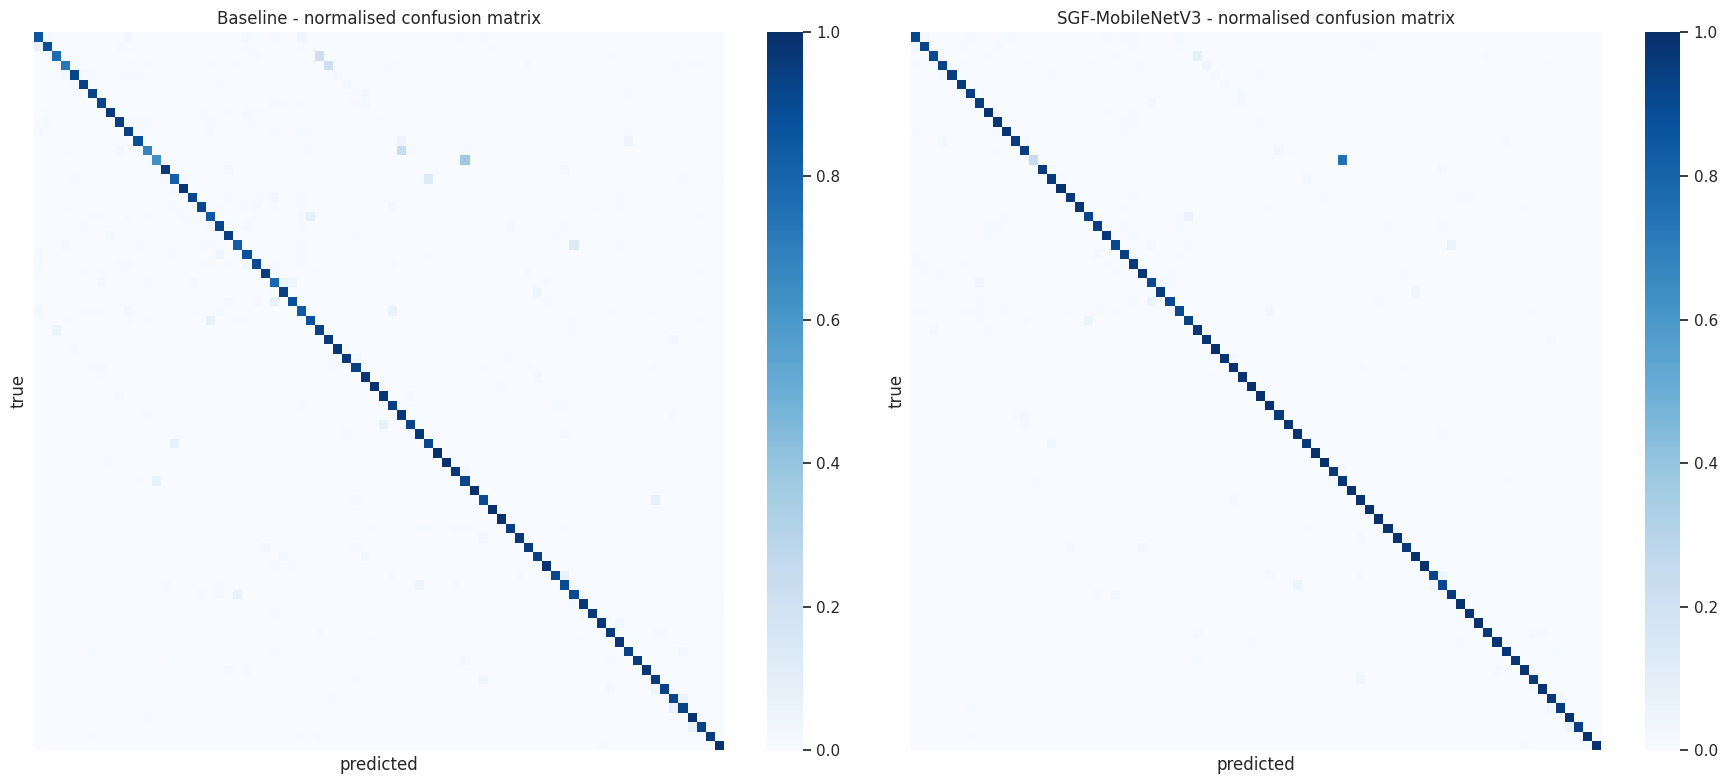

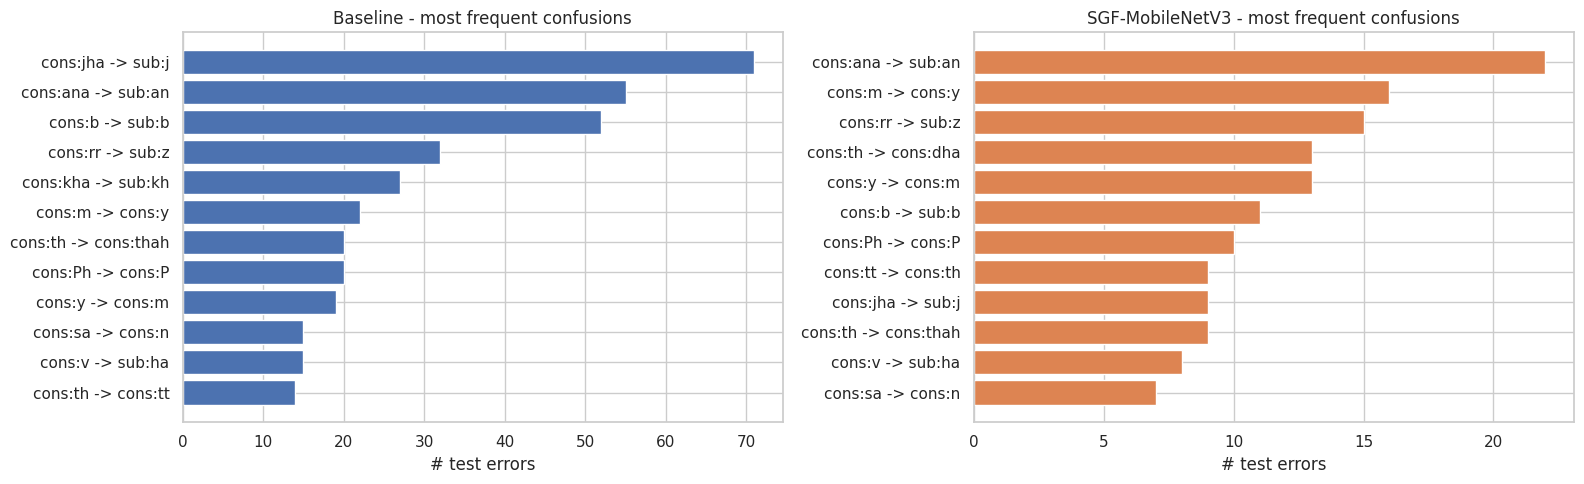

In [16]:
# confusion matrices (normalised) + most confused pairs
def plot_confusion(name, ax):
    yt, yp = PRED[name]["y_true"], PRED[name]["y_pred"]
    cm = confusion_matrix(yt, yp, labels=list(range(NUM_CLASSES))).astype(float)
    cm = cm / np.maximum(cm.sum(1, keepdims=True), 1)
    big = NUM_CLASSES > 60
    sns.heatmap(cm, ax=ax, cmap="Blues", vmin=0, vmax=1, cbar=True,
                xticklabels=False if big else SHORT_NAMES, yticklabels=False if big else SHORT_NAMES)
    ax.set_title(f"{MODEL_SPECS[name]['short']} - normalised confusion matrix"); ax.set_xlabel("predicted"); ax.set_ylabel("true")

fig, axes = plt.subplots(1, 2, figsize=(18, 8))
for a, n in zip(axes, MODEL_SPECS): plot_confusion(n, a)
savefig("07_confusion_matrices.png")

def top_confusions(name, k=12):
    yt, yp = PRED[name]["y_true"], PRED[name]["y_pred"]
    pairs = Counter((SHORT_NAMES[a], SHORT_NAMES[b]) for a, b in zip(yt, yp) if a != b)
    return pairs.most_common(k)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for a, n in zip(axes, MODEL_SPECS):
    tc = top_confusions(n)
    if tc:
        a.barh([f"{p[0]} -> {p[1]}" for p, _ in tc][::-1], [c for _, c in tc][::-1], color=colors[n])
    a.set_title(f"{MODEL_SPECS[n]['short']} - most frequent confusions"); a.set_xlabel("# test errors")
savefig("08_top_confusions.png")

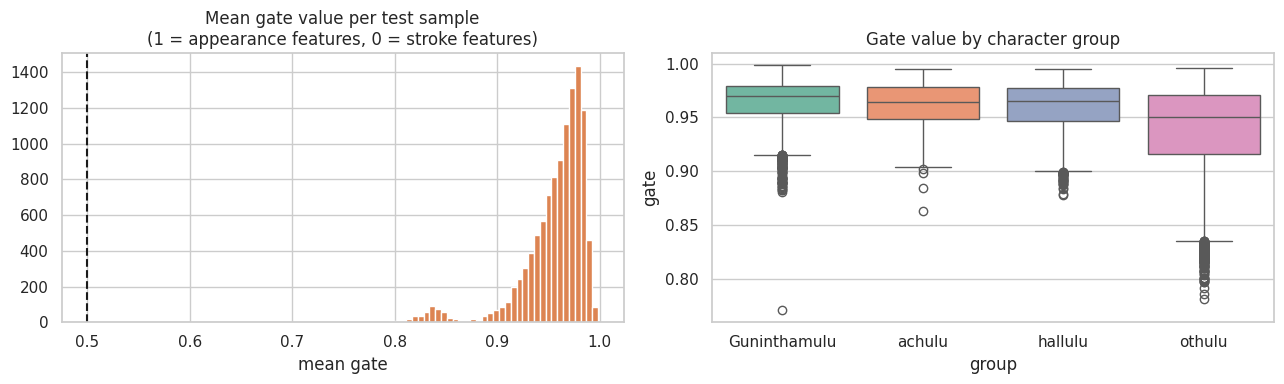

mean gate = 0.956  (appearance share ~96%, stroke share ~4%)


In [17]:
# gate analysis (SGF only): how much does the model rely on appearance vs stroke features?
gate = PRED["Model2_SGF_MobileNetV3_Proposed"]["gate"]
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(gate, bins=40, color=colors["Model2_SGF_MobileNetV3_Proposed"])
axes[0].axvline(0.5, c="k", ls="--"); axes[0].set_title("Mean gate value per test sample\n(1 = appearance features, 0 = stroke features)"); axes[0].set_xlabel("mean gate")
yt = PRED["Model2_SGF_MobileNetV3_Proposed"]["y_true"]
gg = pd.DataFrame(dict(group=test_group, gate=gate))
sns.boxplot(data=gg, x="group", y="gate", order=[g for g in GROUPS if g in set(gg["group"])], ax=axes[1], palette="Set2")
axes[1].set_title("Gate value by character group")
savefig("09_gate_analysis.png")
print(f"mean gate = {gate.mean():.3f}  (appearance share ~{gate.mean()*100:.0f}%, stroke share ~{(1-gate.mean())*100:.0f}%)")

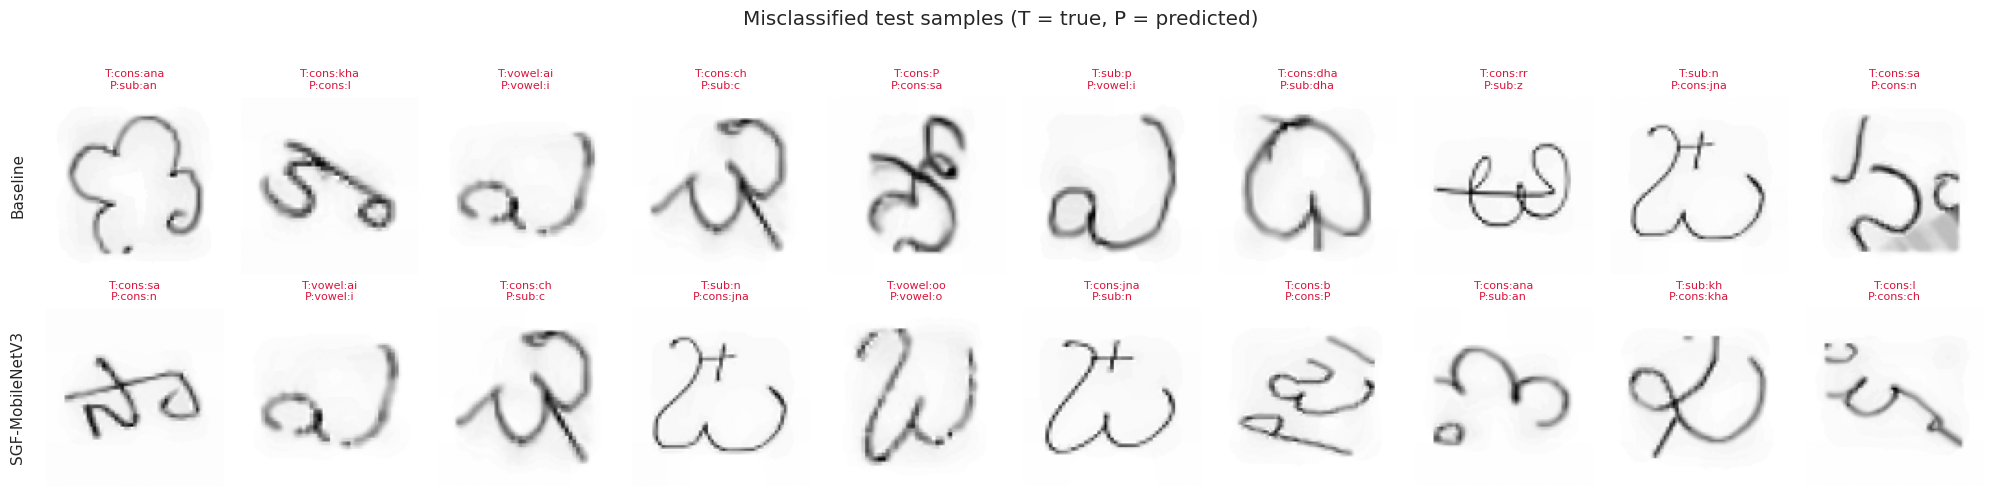

In [18]:
# misclassified examples (test set) for both models
test_X = X[idx_test]
fig, axes = plt.subplots(2, 10, figsize=(20, 5))
for r, name in enumerate(MODEL_SPECS):
    yt, yp = PRED[name]["y_true"], PRED[name]["y_pred"]
    wrong = np.where(yt != yp)[0]
    sel = wrong[:10]
    for c in range(10):
        ax = axes[r, c]; ax.axis("off")
        if c < len(sel):
            i = sel[c]; ax.imshow(test_X[i], cmap="gray")
            ax.set_title(f"T:{SHORT_NAMES[yt[i]][-9:]}\nP:{SHORT_NAMES[yp[i]][-9:]}", fontsize=8, color="crimson")
    axes[r, 0].text(-0.2, 0.5, MODEL_SPECS[name]["short"], transform=axes[r, 0].transAxes, rotation=90, va="center", fontsize=11)
plt.suptitle("Misclassified test samples (T = true, P = predicted)", y=1.02)
savefig("10_misclassified_examples.png")

### 9.1 Upload test - does it work on images that look like a real user upload?
Test images are re-loaded from the **raw files**, then degraded the way uploads are (extra white margins, random size, JPEG compression, blur) and sent through the **same pipeline the Flask app uses** (`preprocess_gray` -> model). `predict_file()` lets you try your own single-character image and prints the top-5 guesses.


In [19]:
def simulate_upload(raw, rng):
    g = raw.copy(); h, w = g.shape
    bg = int(np.percentile(g, 90))
    ml, mr = (rng.uniform(0, 1.0, 2) * w).astype(int); mt, mb = (rng.uniform(0, 1.0, 2) * h).astype(int)
    g = cv2.copyMakeBorder(g, mt, mb, ml, mr, cv2.BORDER_CONSTANT, value=bg)             # white margins / off-centre
    s_ = rng.uniform(0.4, 2.0)
    g = cv2.resize(g, None, fx=s_, fy=s_, interpolation=cv2.INTER_AREA if s_ < 1 else cv2.INTER_CUBIC)
    ok, enc = cv2.imencode(".jpg", g, [cv2.IMWRITE_JPEG_QUALITY, int(rng.integers(35, 95))])   # compression
    g = cv2.imdecode(enc, cv2.IMREAD_GRAYSCALE)
    if rng.random() < 0.3: g = cv2.GaussianBlur(g, (5, 5), 0)
    return g

@torch.no_grad()
def predict_grays(model, uses_stroke, grays, bs=256):
    model.eval(); out = []
    for i in range(0, len(grays), bs):
        b = grays[i:i + bs]
        x = torch.from_numpy(np.stack(b)).float().div(255.).unsqueeze(1).to(DEVICE)
        s = torch.from_numpy(np.stack([compute_stroke_maps(g) for g in b])).to(DEVICE)
        out.append(F.softmax(fwd(model, x, s, uses_stroke).float(), 1).cpu().numpy())
    return np.concatenate(out)

rng_u = np.random.default_rng(11)
sel_idx = rng_u.choice(idx_test, size=min(3000, len(idx_test)), replace=False)
raws = [load_image_gray(df["path"].iloc[j]) for j in sel_idx]
clean_in  = [preprocess_gray(r, IMG_SIZE) for r in raws]
upload_in = [preprocess_gray(simulate_upload(r, rng_u), IMG_SIZE) for r in raws]
y_sel = y[sel_idx]; grp_sel = df["group"].values[sel_idx]
UPLOAD_RESULTS = {}
rows = []
for name, spec in MODEL_SPECS.items():
    pc = predict_grays(MODELS[name], spec["uses_stroke"], clean_in).argmax(1)
    pu = predict_grays(MODELS[name], spec["uses_stroke"], upload_in).argmax(1)
    UPLOAD_RESULTS[name] = dict(clean=float((pc == y_sel).mean()), upload=float((pu == y_sel).mean()))
    row = dict(model=spec["short"], clean_acc=UPLOAD_RESULTS[name]["clean"], upload_acc=UPLOAD_RESULTS[name]["upload"])
    for g in GROUPS:
        m = grp_sel == g
        if m.sum(): row[f"upload_{g}"] = float((pu[m] == y_sel[m]).mean())
    rows.append(row)
upload_df = pd.DataFrame(rows).set_index("model"); display(upload_df.round(4))
upload_df.to_csv(os.path.join(REP_DIR, "upload_simulation.csv"))

def predict_file(path_or_bytes, model_name=None, topk=5, show=True):
    # try your own single-character image (path or raw bytes)
    name = model_name or globals().get("SELECTED", "Model2_SGF_MobileNetV3_Proposed")
    data = path_or_bytes if isinstance(path_or_bytes, (bytes, bytearray)) else open(path_or_bytes, "rb").read()
    raw = decode_gray(data)
    if raw is None: raise ValueError("unreadable image")
    pre = preprocess_gray(raw, IMG_SIZE)
    p = predict_grays(MODELS[name], MODEL_SPECS[name]["uses_stroke"], [pre])[0]
    top = np.argsort(-p)[:topk]
    if show:
        fig, ax = plt.subplots(1, 2, figsize=(5, 2.6)); ax[0].imshow(raw, cmap="gray"); ax[0].set_title("uploaded"); ax[1].imshow(pre, cmap="gray"); ax[1].set_title("model input")
        for a in ax: a.axis("off")
        plt.show()
    for r, i in enumerate(top, 1): print(f"{r}. {IDX2UNI[int(i)]}   {CLASS_KEYS[int(i)]:22s} {p[i]:.3f}")
    if p[top[0]] < 0.5: print("-> low confidence: image may be unclear, cropped, or not one of the trained characters")
    return [(IDX2UNI[int(i)], CLASS_KEYS[int(i)], float(p[i])) for i in top]

# example: predict_file("/kaggle/input/.../your_character.png")


,clean_acc,upload_acc,upload_Guninthamulu,upload_achulu,upload_hallulu,upload_othulu
model,,,,,,
Baseline,0.9067,0.8510,0.8300,0.8829,0.8070,0.9146
SGF-MobileNetV3,0.9607,0.9063,0.8777,0.9390,0.9021,0.9392


## 10. Latency, parameters and model size
Latency is measured with batch size 1 (typical for a Flask service). For Model 2 the **end-to-end** CPU latency also includes stroke-feature extraction.

preprocessing: 10.48 ms/img | stroke-feature extraction: 0.40 ms/img


,params_M,size_MB,cpu_model_ms_mean,cpu_model_ms_p95,cpu_end2end_ms,cpu_throughput_img_s,gpu_model_ms_mean,gpu_throughput_img_s
model,,,,,,,,
Model1_MobileNetV3Small_Baseline,0.194,0.859,4.296,4.723,14.780,1199.642,3.511,16984.741
Model2_SGF_MobileNetV3_Proposed,1.406,5.785,7.332,7.870,18.221,659.886,5.848,9048.721


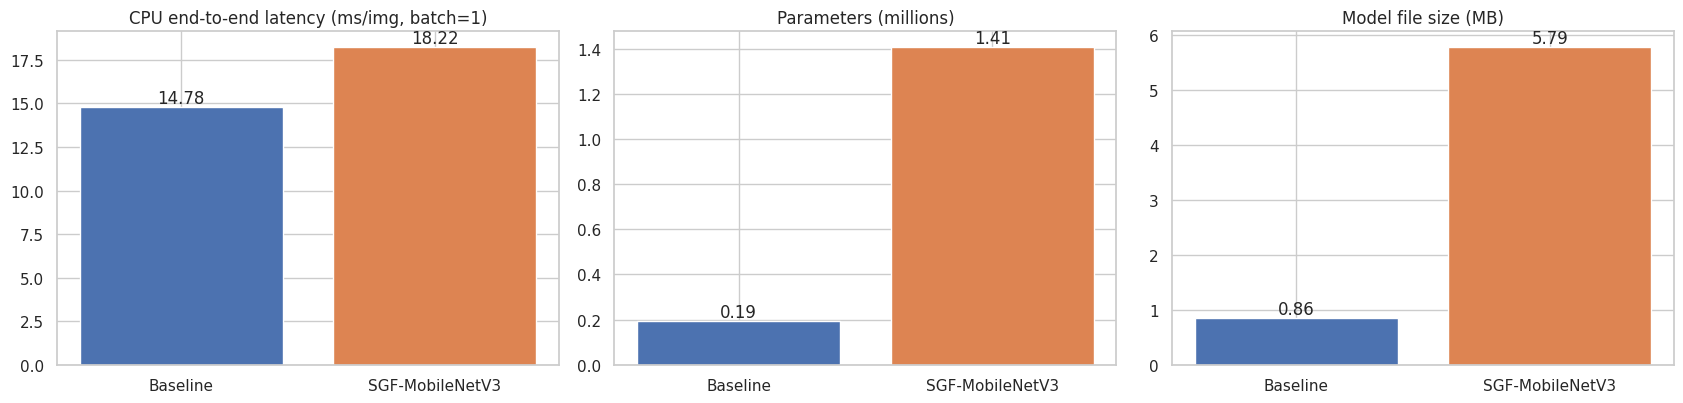

In [20]:
@torch.no_grad()
def bench_latency(model, uses_stroke, device, n=200, warmup=30):
    m = copy.deepcopy(model).to(device).eval()
    x = torch.rand(1, 1, IMG_SIZE, IMG_SIZE, device=device); s = torch.rand(1, 3, IMG_SIZE, IMG_SIZE, device=device)
    def sync():
        if device.type == "cuda": torch.cuda.synchronize()
    for _ in range(warmup): fwd(m, x, s, uses_stroke)
    sync(); ts = []
    for _ in range(n):
        t = time.perf_counter(); fwd(m, x, s, uses_stroke); sync(); ts.append((time.perf_counter() - t) * 1000)
    return np.array(ts)

@torch.no_grad()
def bench_throughput(model, uses_stroke, device, bs=64, n=20):
    m = copy.deepcopy(model).to(device).eval()
    x = torch.rand(bs, 1, IMG_SIZE, IMG_SIZE, device=device); s = torch.rand(bs, 3, IMG_SIZE, IMG_SIZE, device=device)
    for _ in range(3): fwd(m, x, s, uses_stroke)
    if device.type == "cuda": torch.cuda.synchronize()
    t = time.perf_counter()
    for _ in range(n): fwd(m, x, s, uses_stroke)
    if device.type == "cuda": torch.cuda.synchronize()
    return bs * n / (time.perf_counter() - t)

# cost of stroke-feature extraction / preprocessing (CPU, per image)
sample_gray = X[np.random.default_rng(1).choice(len(X), 200, replace=False)]
t = time.perf_counter(); [compute_stroke_maps(g) for g in sample_gray]; STROKE_MS = (time.perf_counter() - t) / len(sample_gray) * 1000
raw_samples = [load_image_gray(p) for p in df["path"].sample(100, random_state=1)]
t = time.perf_counter(); [preprocess_gray(r, IMG_SIZE) for r in raw_samples]; PREP_MS = (time.perf_counter() - t) / len(raw_samples) * 1000
print(f"preprocessing: {PREP_MS:.2f} ms/img | stroke-feature extraction: {STROKE_MS:.2f} ms/img")

CPU = torch.device("cpu")
lat_rows = []
for name, spec in MODEL_SPECS.items():
    cpu_t = bench_latency(MODELS[name], spec["uses_stroke"], CPU)
    row = dict(model=name, params_M=count_params(MODELS[name]) / 1e6,
               size_MB=os.path.getsize(os.path.join(MODEL_DIR, f"{name}.pth")) / 1e6,
               cpu_model_ms_mean=cpu_t.mean(), cpu_model_ms_p95=np.percentile(cpu_t, 95),
               cpu_end2end_ms=cpu_t.mean() + PREP_MS + (STROKE_MS if spec["uses_stroke"] else 0),
               cpu_throughput_img_s=bench_throughput(MODELS[name], spec["uses_stroke"], CPU, bs=64, n=5))
    if DEVICE.type == "cuda":
        g_t = bench_latency(MODELS[name], spec["uses_stroke"], DEVICE)
        row.update(gpu_model_ms_mean=g_t.mean(), gpu_throughput_img_s=bench_throughput(MODELS[name], spec["uses_stroke"], DEVICE))
    lat_rows.append(row)
lat_df = pd.DataFrame(lat_rows).set_index("model")
display(lat_df.round(3))

fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
short = [MODEL_SPECS[n]["short"] for n in lat_df.index]; cl = [colors[n] for n in lat_df.index]
axes[0].bar(short, lat_df.cpu_end2end_ms, color=cl); axes[0].set_title("CPU end-to-end latency (ms/img, batch=1)")
axes[1].bar(short, lat_df.params_M, color=cl); axes[1].set_title("Parameters (millions)")
axes[2].bar(short, lat_df.size_MB, color=cl); axes[2].set_title("Model file size (MB)")
for a in axes:
    for c in a.containers: a.bar_label(c, fmt="%.2f")
savefig("11_latency_params_size.png")

## 11. Performance comparison & model selection

,accuracy,precision_macro,recall_macro,f1_macro,f1_weighted,top3_accuracy,cpu_end2end_ms,cpu_model_ms_mean,params_M,size_MB,best_epoch,train_time_min
Baseline,0.9074,0.8997,0.9231,0.9069,0.9089,0.9861,14.7804,4.2964,0.1942,0.8590,30.0,17.7028
SGF-MobileNetV3,0.9590,0.9533,0.9571,0.9534,0.9589,0.9948,18.2209,7.3320,1.4065,5.7855,29.0,22.6105


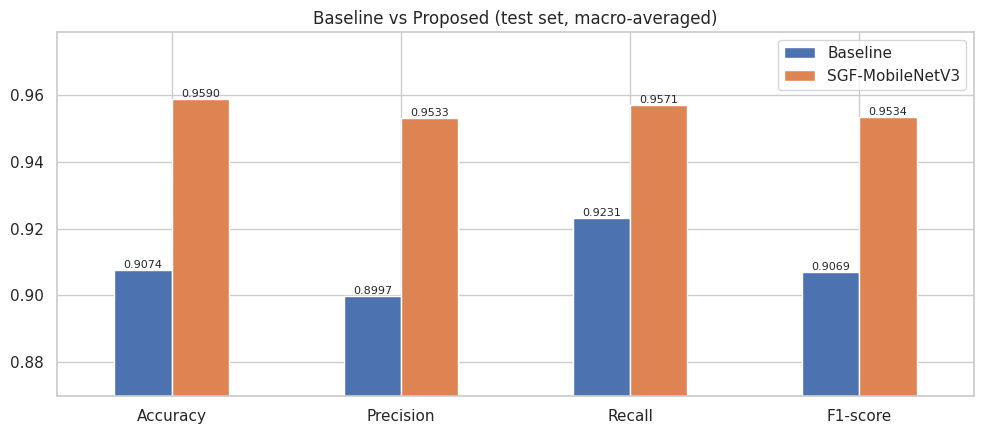

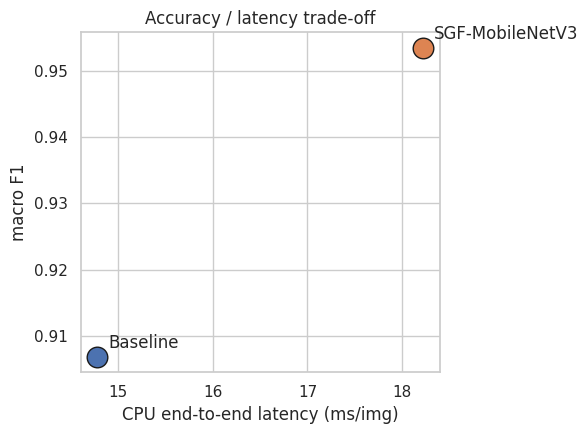

In [21]:
comp = metrics_df[["accuracy", "precision_macro", "recall_macro", "f1_macro", "f1_weighted", "top3_accuracy"]].join(
    lat_df[["cpu_end2end_ms", "cpu_model_ms_mean", "params_M", "size_MB"]])
for k, v in TRAIN_INFO.items():
    comp.loc[k, "best_epoch"] = v["best_epoch"]; comp.loc[k, "train_time_min"] = v["train_time_s"] / 60
comp.index = [MODEL_SPECS[i]["short"] for i in comp.index]
display(comp.round(4))
comp.to_csv(os.path.join(REP_DIR, "model_comparison.csv"))

# grouped bar chart of the four headline metrics
plot_df = comp[["accuracy", "precision_macro", "recall_macro", "f1_macro"]].T
plot_df.index = ["Accuracy", "Precision", "Recall", "F1-score"]
ax = plot_df.plot(kind="bar", figsize=(10, 4.5), color=[colors[n] for n in MODEL_SPECS], rot=0)
for c in ax.containers: ax.bar_label(c, fmt="%.4f", fontsize=8)
lo = max(0, plot_df.values.min() - 0.03); ax.set_ylim(lo, min(1.02, plot_df.values.max() + 0.02))
ax.set_title("Baseline vs Proposed (test set, macro-averaged)"); plt.legend(title="")
savefig("12_model_comparison.png")

# radar-style trade-off: accuracy vs latency
fig, ax = plt.subplots(figsize=(6, 4.5))
for n in MODEL_SPECS:
    s = MODEL_SPECS[n]["short"]
    ax.scatter(comp.loc[s, "cpu_end2end_ms"], comp.loc[s, "f1_macro"], s=220, color=colors[n], label=s, edgecolor="k")
    ax.annotate(s, (comp.loc[s, "cpu_end2end_ms"], comp.loc[s, "f1_macro"]), textcoords="offset points", xytext=(8, 6))
ax.set_xlabel("CPU end-to-end latency (ms/img)"); ax.set_ylabel("macro F1"); ax.set_title("Accuracy / latency trade-off")
savefig("13_accuracy_vs_latency.png")

In [22]:
# Selection rule: highest macro-F1; if the gap is <= TOL, prefer the faster model.
TOL = 0.005
names = list(MODEL_SPECS)
f1 = {n: RESULTS[n]["f1_macro"] for n in names}
lat = {n: lat_df.loc[n, "cpu_end2end_ms"] for n in names}
best_f1 = max(f1, key=f1.get)
close = [n for n in names if f1[best_f1] - f1[n] <= TOL]
SELECTED = min(close, key=lambda n: lat[n])
print("macro-F1 :", {MODEL_SPECS[n]["short"]: round(f1[n], 4) for n in names})
print("latency  :", {MODEL_SPECS[n]["short"]: round(lat[n], 2) for n in names}, "ms")
print(f"\n>>> Selected model: {SELECTED}  ({MODEL_SPECS[SELECTED]['short']})")
print("    reason:", "highest macro-F1" if SELECTED == best_f1 else f"macro-F1 within {TOL} of the best and lower latency")

macro-F1 : {'Baseline': 0.9069, 'SGF-MobileNetV3': 0.9534}
latency  : {'Baseline': np.float64(14.78), 'SGF-MobileNetV3': np.float64(18.22)} ms

>>> Selected model: Model2_SGF_MobileNetV3_Proposed  (SGF-MobileNetV3)
    reason: highest macro-F1


## 12. Save models, mappings and metrics
For each model: PyTorch `state_dict` (`.pth`), a full checkpoint with metadata, a **TorchScript** file (loadable without the class definitions – used by Flask) and an **ONNX** file. The selected model is additionally copied to `best_model.*`.

In [23]:
class_map = {"idx_to_key": {i: k for i, k in enumerate(CLASS_KEYS)},
             "idx_to_unicode": {int(i): u for i, u in IDX2UNI.items()}}
with open(os.path.join(MODEL_DIR, "class_mapping.json"), "w", encoding="utf-8") as f:
    json.dump(class_map, f, ensure_ascii=False, indent=1)

def export_model(name):
    spec, model = MODEL_SPECS[name], MODELS[name].eval().cpu()
    meta = dict(model_name=name, uses_stroke=spec["uses_stroke"], img_size=IMG_SIZE, num_classes=NUM_CLASSES,
                class_keys=CLASS_KEYS, idx_to_unicode={int(k): v for k, v in IDX2UNI.items()},
                test_metrics=RESULTS[name], train_info=TRAIN_INFO[name])
    paths = {}
    p = os.path.join(MODEL_DIR, f"{name}.pth"); torch.save(model.state_dict(), p); paths["state_dict"] = p
    p = os.path.join(MODEL_DIR, f"{name}_checkpoint.pt"); torch.save(dict(state_dict=model.state_dict(), meta=meta), p); paths["checkpoint"] = p
    x = torch.rand(1, 1, IMG_SIZE, IMG_SIZE); s = torch.rand(1, 3, IMG_SIZE, IMG_SIZE)
    ex_inputs = (x, s) if spec["uses_stroke"] else (x,)
    try:
        ts = torch.jit.trace(model, ex_inputs, check_trace=False)
        p = os.path.join(MODEL_DIR, f"{name}_torchscript.pt"); ts.save(p); paths["torchscript"] = p
    except Exception as e:
        print(f"  [warn] TorchScript export failed for {name}: {e}")
    try:
        p = os.path.join(MODEL_DIR, f"{name}.onnx")
        torch.onnx.export(model, ex_inputs, p, opset_version=17,
                          input_names=["gray", "stroke"][:len(ex_inputs)], output_names=["logits"],
                          dynamic_axes={k: {0: "batch"} for k in (["gray", "stroke"][:len(ex_inputs)] + ["logits"])})
        paths["onnx"] = p
    except Exception as e:
        print(f"  [warn] ONNX export failed for {name}: {e}")
    with open(os.path.join(MODEL_DIR, f"{name}_meta.json"), "w", encoding="utf-8") as f:
        json.dump(meta, f, ensure_ascii=False, indent=1, default=float)
    return paths

SAVED = {n: export_model(n) for n in MODEL_SPECS}
MODELS = {n: m.to(DEVICE) for n, m in MODELS.items()}

# selected model -> best_model.*
for kind, path in SAVED[SELECTED].items():
    ext = os.path.splitext(path)[1]
    suffix = {"state_dict": ".pth", "checkpoint": "_checkpoint.pt", "torchscript": "_torchscript.pt", "onnx": ".onnx"}[kind]
    shutil.copy(path, os.path.join(MODEL_DIR, f"best_model{suffix}"))
shutil.copy(os.path.join(MODEL_DIR, f"{SELECTED}_meta.json"), os.path.join(MODEL_DIR, "best_model_meta.json"))

# metrics bundle
with open(os.path.join(REP_DIR, "metrics_summary.json"), "w", encoding="utf-8") as f:
    json.dump(dict(selected_model=SELECTED, test_metrics=RESULTS, latency=lat_df.to_dict("index"),
                   preprocessing_ms=PREP_MS, stroke_extraction_ms=STROKE_MS,
                   split=dict(train=len(idx_train), val=len(idx_val), test=len(idx_test)),
                   config=dict(IMG_SIZE=IMG_SIZE, BATCH_SIZE=BATCH_SIZE, EPOCHS=EPOCHS, LR=LR, SEED=SEED)),
              f, indent=1, default=float)

print("Saved files:")
for root, _, files in os.walk(OUT_DIR):
    if any(s in root for s in ("models", "reports", "figures")) or root == OUT_DIR:
        for fn in sorted(files):
            fp = os.path.join(root, fn)
            if fn.endswith((".pth", ".pt", ".onnx", ".json", ".csv", ".png", ".py")):
                print(f"  {os.path.relpath(fp, OUT_DIR):65s} {os.path.getsize(fp)/1e6:8.2f} MB")

  [warn] ONNX export failed for Model1_MobileNetV3Small_Baseline: No module named 'onnxscript'
  [warn] ONNX export failed for Model2_SGF_MobileNetV3_Proposed: No module named 'onnxscript'
Saved files:
  ocr_utils.py                                                          0.01 MB
  telugu_unicode.py                                                     0.00 MB
  figures/01_dataset_distribution.png                                   0.07 MB
  figures/02_preprocessing_before_after.png                             0.12 MB
  figures/03_stroke_features.png                                        0.15 MB
  figures/04_training_curves.png                                        0.18 MB
  figures/05_per_class_f1.png                                           0.09 MB
  figures/06_accuracy_per_group.png                                     0.06 MB
  figures/07_confusion_matrices.png                                     0.05 MB
  figures/08_top_confusions.png                                         0.10 M

## 13. Telugu Unicode conversion → dictionary-based correction → final text

1. The selected model predicts a class for each character image.
2. The class index is converted to **Telugu Unicode** (`IDX2UNI`).
3. The character string is split into aksharas and compared with a **Telugu word dictionary** (edit distance over aksharas); the closest word within the distance budget replaces the raw prediction.

Provide your own dictionary with `DICT_FILE` (one Telugu word per line, UTF-8). A small built-in list is used otherwise.

In [24]:
DICT_FILE = None   # e.g. "/kaggle/input/<your-dataset>/telugu_words.txt"

BUILTIN_WORDS = """తెలుగు అమ్మ నాన్న అన్న అక్క తమ్ముడు చెల్లి నీరు పాలు పండు పూలు చెట్టు ఇల్లు బడి పుస్తకం కలము
రాముడు కృష్ణుడు భారతదేశం ఆంధ్ర తల్లి తండ్రి స్నేహితుడు గురువు విద్యార్థి పాఠశాల ఆవు గుర్రం పిల్లి కుక్క చేపలు
పక్షి సూర్యుడు చంద్రుడు నక్షత్రం ఆకాశం భూమి గాలి నిప్పు వర్షం కథ పాట నది కొండ అడవి పట్టణం గ్రామం""".split()

if DICT_FILE and os.path.exists(DICT_FILE):
    with open(DICT_FILE, encoding="utf-8") as f: WORDS = [w.strip() for w in f if w.strip()]
else:
    WORDS = BUILTIN_WORDS
DICT_UNITS = {w: telugu_units(w) for w in dict.fromkeys(WORDS)}
print("dictionary size:", len(DICT_UNITS))

@torch.no_grad()
def predict_characters(model, uses_stroke, gray_imgs):
    # gray_imgs: list of preprocessed (IMG_SIZE x IMG_SIZE) uint8 arrays -> (indices, confidences)
    model.eval()
    x = torch.from_numpy(np.stack(gray_imgs)).float().div(255.).unsqueeze(1).to(DEVICE)
    s = torch.from_numpy(np.stack([compute_stroke_maps(g) for g in gray_imgs])).to(DEVICE)
    p = F.softmax(fwd(model, x, s, uses_stroke).float(), 1)
    conf, idx = p.max(1)
    return idx.cpu().numpy(), conf.cpu().numpy()

def recognize_word(model, uses_stroke, gray_imgs):
    idx, conf = predict_characters(model, uses_stroke, gray_imgs)
    raw = "".join(IDX2UNI[int(i)] for i in idx)
    fixed, dist = correct_word(raw, DICT_UNITS)
    return raw, fixed, dist, conf

# Build demo "words": pick dictionary words whose every akshara exists as a class, then draw one test image per akshara
uni2idx = {}
for i, u in IDX2UNI.items(): uni2idx.setdefault(u, []).append(i)
test_by_class = {}
for j, lab in zip(idx_test, y[idx_test]): test_by_class.setdefault(int(lab), []).append(int(j))

def make_word_images(word, rng):
    imgs = []
    for u in telugu_units(word):
        cands = [c for c in uni2idx.get(u, []) if c in test_by_class]
        if not cands: return None
        imgs.append(X[rng.choice(test_by_class[int(rng.choice(cands))])])
    return imgs

rng = np.random.default_rng(7)
demo = []
for w in DICT_UNITS:
    ims = make_word_images(w, rng)
    if ims is not None: demo.append((w, ims))
print(f"{len(demo)} dictionary words can be assembled from the available character classes")

dictionary size: 47
1 dictionary words can be assembled from the available character classes


,ground_truth,raw_prediction,after_dictionary,edit_dist,mean_conf
0,కథ,కథ,కథ,0,0.941052


word accuracy BEFORE dictionary correction: 1.000
word accuracy AFTER  dictionary correction: 1.000   (n=1 words)

Simulated 1-akshara OCR error: dictionary recovers the right word in 50.2% of 235 cases


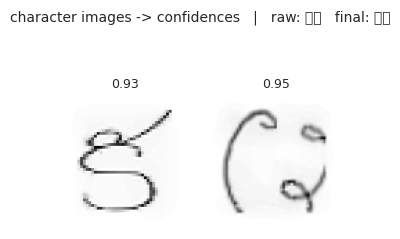

In [25]:
sel_spec = MODEL_SPECS[SELECTED]; sel_model = MODELS[SELECTED]
n_demo = min(len(demo), 200)
raw_ok = fix_ok = 0; shown = []
for w, ims in demo[:n_demo]:
    raw, fixed, dist, conf = recognize_word(sel_model, sel_spec["uses_stroke"], ims)
    raw_ok += raw == w; fix_ok += fixed == w
    if len(shown) < 8: shown.append((w, raw, fixed, dist, float(conf.mean())))
if n_demo:
    res = pd.DataFrame(shown, columns=["ground_truth", "raw_prediction", "after_dictionary", "edit_dist", "mean_conf"])
    display(res)
    print(f"word accuracy BEFORE dictionary correction: {raw_ok/n_demo:.3f}")
    print(f"word accuracy AFTER  dictionary correction: {fix_ok/n_demo:.3f}   (n={n_demo} words)")
else:
    print("No dictionary words could be assembled - check the Unicode mapping above (MANUAL_UNICODE).")

# stress test: simulate character-level OCR errors on every dictionary word and measure how many the dictionary repairs
rng2 = np.random.default_rng(3); all_units = [u for u in uni2idx]
def corrupt(word):
    u = telugu_units(word); k = rng2.integers(len(u)); u[k] = all_units[rng2.integers(len(all_units))]; return "".join(u)
tests = [(w, corrupt(w)) for w in DICT_UNITS for _ in range(5)]
rec = np.mean([correct_word(c, DICT_UNITS)[0] == w for w, c in tests])
print(f"\nSimulated 1-akshara OCR error: dictionary recovers the right word in {rec*100:.1f}% of {len(tests)} cases")

# visual: one word end-to-end
if demo:
    w, ims = demo[0]; raw, fixed, dist, conf = recognize_word(sel_model, sel_spec["uses_stroke"], ims)
    fig, axes = plt.subplots(1, len(ims), figsize=(1.6 * len(ims), 2.2))
    for a, im, c in zip(np.atleast_1d(axes), ims, conf): a.imshow(im, cmap="gray"); a.axis("off"); a.set_title(f"{c:.2f}", fontsize=9)
    plt.suptitle("character images -> confidences   |   raw: " + raw + "   final: " + fixed, y=1.12, fontsize=10)
    savefig("14_word_pipeline_demo.png")

## 14. Flask + PyTorch serving skeleton (from the blueprint footer)
Writes `flask_app/` with `app.py`, the selected TorchScript model, the class mapping and `ocr_utils.py` (the same preprocessing used for training).

In [26]:
APP_SRC = r"""
import os, io, json
import numpy as np, cv2, torch
from flask import Flask, request, jsonify
from ocr_utils import decode_gray, preprocess_gray, compute_stroke_maps, correct_word, telugu_units

HERE = os.path.dirname(os.path.abspath(__file__))
META = json.load(open(os.path.join(HERE, "best_model_meta.json"), encoding="utf-8"))
IDX2UNI = {int(k): v for k, v in META["idx_to_unicode"].items()}
SIZE, USES_STROKE = META["img_size"], META["uses_stroke"]
MODEL = torch.jit.load(os.path.join(HERE, "best_model_torchscript.pt"), map_location="cpu").eval()

WORDS = []
dict_path = os.path.join(HERE, "telugu_words.txt")
if os.path.exists(dict_path):
    WORDS = [w.strip() for w in open(dict_path, encoding="utf-8") if w.strip()]
DICT_UNITS = {w: telugu_units(w) for w in WORDS}

app = Flask(__name__)

def read_gray(file_storage):
    # SAME loader + pre-processing as training (handles transparent PNGs, tight/loose crops)
    img = decode_gray(file_storage.read())
    if img is None:
        raise ValueError("unreadable image")
    return preprocess_gray(img, SIZE)

@torch.no_grad()
def probs(grays):
    x = torch.from_numpy(np.stack(grays)).float().div(255.).unsqueeze(1)
    if USES_STROKE:
        s = torch.from_numpy(np.stack([compute_stroke_maps(g) for g in grays]))
        logits = MODEL(x, s)
    else:
        logits = MODEL(x)
    return torch.softmax(logits, 1).numpy()

def predict(grays):
    p = probs(grays)
    return p.argmax(1).tolist(), p.max(1).tolist()

@app.errorhandler(ValueError)
def bad_image(e):
    return jsonify(error=str(e)), 400

@app.route("/health")
def health():
    return jsonify(status="ok", model=META["model_name"])

@app.route("/predict_char", methods=["POST"])
def predict_char():
    p = probs([read_gray(request.files["image"])])[0]
    top = np.argsort(-p)[:5]
    return jsonify(unicode=IDX2UNI[int(top[0])], class_key=META["class_keys"][int(top[0])], confidence=float(p[top[0]]),
                   low_confidence=bool(p[top[0]] < 0.5),
                   top5=[dict(unicode=IDX2UNI[int(i)], class_key=META["class_keys"][int(i)], confidence=float(p[i])) for i in top])

@app.route("/predict_word", methods=["POST"])
def predict_word():
    # upload several character images (field name "images"), ordered left -> right
    grays = [read_gray(f) for f in request.files.getlist("images")]
    idx, conf = predict(grays)
    raw = "".join(IDX2UNI[i] for i in idx)
    fixed, dist = correct_word(raw, DICT_UNITS) if DICT_UNITS else (raw, -1)
    return jsonify(raw=raw, corrected=fixed, edit_distance=dist, confidences=conf)

if __name__ == "__main__":
    app.run(host="0.0.0.0", port=5000)
"""
APP_DIR = os.path.join(OUT_DIR, "flask_app"); os.makedirs(APP_DIR, exist_ok=True)
with open(os.path.join(APP_DIR, "app.py"), "w", encoding="utf-8") as f: f.write(APP_SRC)
with open(os.path.join(APP_DIR, "telugu_words.txt"), "w", encoding="utf-8") as f: f.write("\n".join(WORDS))
with open(os.path.join(APP_DIR, "requirements.txt"), "w") as f: f.write("flask\ntorch\nopencv-python-headless\nscikit-image\nnumpy\n")
shutil.copy(os.path.join(OUT_DIR, "ocr_utils.py"), APP_DIR)
for fn in ("best_model_torchscript.pt", "best_model_meta.json"):
    if os.path.exists(os.path.join(MODEL_DIR, fn)): shutil.copy(os.path.join(MODEL_DIR, fn), APP_DIR)
print("Flask app written to", APP_DIR, "->", sorted(os.listdir(APP_DIR)))
print("Run:  cd flask_app && pip install -r requirements.txt && python app.py")

Flask app written to /kaggle/working/flask_app -> ['app.py', 'best_model_meta.json', 'best_model_torchscript.pt', 'ocr_utils.py', 'requirements.txt', 'telugu_words.txt']
Run:  cd flask_app && pip install -r requirements.txt && python app.py


## 15. Summary

In [27]:
print("=" * 70)
print("FINAL SUMMARY")
print("=" * 70)
display(comp.round(4))
print(f"\nSelected model : {SELECTED}")
print(f"Models saved in: {MODEL_DIR}")
print(f"Figures in     : {FIG_DIR}")
print(f"Reports in     : {REP_DIR}")
print(f"Flask app in   : {os.path.join(OUT_DIR, 'flask_app')}")

FINAL SUMMARY


,accuracy,precision_macro,recall_macro,f1_macro,f1_weighted,top3_accuracy,cpu_end2end_ms,cpu_model_ms_mean,params_M,size_MB,best_epoch,train_time_min
Baseline,0.9074,0.8997,0.9231,0.9069,0.9089,0.9861,14.7804,4.2964,0.1942,0.8590,30.0,17.7028
SGF-MobileNetV3,0.9590,0.9533,0.9571,0.9534,0.9589,0.9948,18.2209,7.3320,1.4065,5.7855,29.0,22.6105



Selected model : Model2_SGF_MobileNetV3_Proposed
Models saved in: /kaggle/working/models
Figures in     : /kaggle/working/figures
Reports in     : /kaggle/working/reports
Flask app in   : /kaggle/working/flask_app


### Project status (computed from this run)


In [28]:
sel = SELECTED; base = "Model1_MobileNetV3Small_Baseline"
f1_sel, f1_base = RESULTS[sel]["f1_macro"], RESULTS[base]["f1_macro"]
up_sel = UPLOAD_RESULTS[sel]["upload"]
n_words = len(demo)
status = pd.DataFrame([
    ["Character-level classification", "Strong results" if (f1_sel >= 0.95 and up_sel >= 0.90) else "Needs work",
     f"macro-F1 {f1_sel:.3f} | balanced acc {RESULTS[sel]['recall_macro']:.3f} | upload-test acc {up_sel:.3f}"],
    ["Proposed model performance", "Promising" if f1_sel > f1_base else "No gain over baseline",
     f"SGF macro-F1 {f1_sel:.3f} vs baseline {f1_base:.3f} (+{(f1_sel - f1_base) * 100:.1f} pts), latency {lat_df.loc[sel, 'cpu_end2end_ms']:.1f} ms"],
    ["Full Telugu OCR validation", "Incomplete" if n_words < 100 else "Partial",
     f"only {n_words} dictionary words could be assembled from character classes; no word/line-image test set yet"],
], columns=["item", "status", "evidence"])
display(status)
status.to_csv(os.path.join(REP_DIR, "project_status.csv"), index=False)


,item,status,evidence
0,Character-level classification,Strong results,macro-F1 0.953 | balanced acc 0.957 | upload-t...
1,Proposed model performance,Promising,SGF macro-F1 0.953 vs baseline 0.907 (+4.6 pts...
2,Full Telugu OCR validation,Incomplete,only 1 dictionary words could be assembled fro...
